# Teorema de Tales

**Módulo:** 04 – Geometria Plana

**Pré-requisitos:** [`0402a_segmento_de_reta.ipynb`](0402a_segmento_de_reta.ipynb) (medida de segmentos, ponto médio e a razão $AP/PB$ dos Desafios 5 e 6), [`0403a_angulos.ipynb`](0403a_angulos.ipynb) (bissetriz de um ângulo), [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) (triângulo isósceles e congruência como ferramenta de prova, em especial o caso **ALA**), [`0406a_paralelismo.ipynb`](0406a_paralelismo.ipynb) (retas paralelas, transversal, ângulos **correspondentes** e **alternos internos**), [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb) e [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb) (base média e propriedades do paralelogramo, usadas no lema da seção 2).

**Objetivos de aprendizagem:** ao final você será capaz de...
- Calcular a **razão** entre dois segmentos, reconhecer **segmentos proporcionais** e dividir um segmento numa razão dada.
- Enunciar e aplicar o **Teorema de Tales** a um feixe de retas paralelas cortado por transversais e a um **triângulo** cortado por uma paralela a um lado.
- Compreender (e reproduzir em código) **por que** o teorema vale, inclusive quando as razões são irracionais.
- Enunciar e aplicar o **teorema da bissetriz interna** (e conhecer o da bissetriz externa), demonstrando o primeiro com o Teorema de Tales.

**Tempo estimado:** 70 a 85 minutos

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leandrofreiredealmeida/curso_matematica_python/blob/main/04_geometria_plana/0414a_teorema_de_tales.ipynb)

## A folha pautada como régua mágica

Você tem uma tira de papel de 14 cm e precisa dividi-la em **7 partes exatamente iguais**, mas não tem régua graduada. Com 14 cm até dá para fazer a conta (2 cm cada parte)... mas e se a tira tivesse 13,3 cm? E se fossem 11 partes?

Existe um truque que funciona com **qualquer** tira e **qualquer** número de partes, e que você pode testar agora mesmo com um caderno:

1. Apoie uma ponta da tira numa linha do caderno pautado (chame essa linha de **linha 0**).
2. Gire a tira até a outra ponta cair exatamente sobre a **sétima linha**, contando a partir da linha 0.
3. Marque na tira os pontos em que as linhas 1, 2, ..., 6 a cortam.

Pronto: as marcas dividem a tira em 7 partes iguais, e ninguém mediu nada! As linhas do caderno são **retas paralelas igualmente espaçadas**, e é só isso que o truque usa.

**Antes de executar:** com a tira de 14 cm, a que distância da ponta fica a marca da **3ª linha**? E se a tira ficar mais "deitada" (menos inclinada), essa distância muda? Faça a sua aposta e rode as células abaixo (a primeira carrega as ferramentas do notebook).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
from matplotlib.patches import Arc, Circle, Polygon, Wedge

# Paleta de cores Nord
NORD_FUNDO = "#2E3440"
NORD_PAINEL = "#3B4252"
NORD_LINHA = "#4C566A"
NORD_TEXTO = "#ECEFF4"
NORD_TEXTO_SEC = "#D8DEE9"
COR_PONTO = "#88C0D0"
COR_DESTAQUE = "#A3BE8C"
COR_ALERTA = "#BF616A"
COR_SECUNDARIA = "#81A1C1"
COR_EXTRA = "#B48EAD"
COR_AVISO = "#EBCB8B"


def estilizar_eixo(ax) -> None:
    """Aplica o estilo Nord padrão a um eixo do matplotlib."""
    ax.set_facecolor(NORD_FUNDO)
    ax.tick_params(colors=NORD_TEXTO_SEC)
    for spine in ax.spines.values():
        spine.set_color(NORD_LINHA)
    ax.grid(color=NORD_LINHA, linewidth=0.5, alpha=0.5)


# Ferramentas de desenho e de medida dos notebooks anteriores (0401a, 0402a, 0407a, 0410a e 0412a)

def preparar_eixo(ax, pontos, margem: float = 0.8) -> None:
    """Deixa o eixo pronto para desenhos de geometria (estilo Nord, sem grade, sem números,
    escala igual) e enquadra todos os `pontos` com uma margem em volta."""
    estilizar_eixo(ax)
    ax.grid(False)
    xs = [p[0] for p in pontos]
    ys = [p[1] for p in pontos]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def direcao(angulo_graus: float) -> np.ndarray:
    """Vetor de tamanho 1 apontando na direção dada, em graus, a partir da horizontal (sentido anti-horário).

    (cos e sin vêm da Trigonometria, módulo 05; aqui só servem para apontar na direção certa.)
    """
    rad = math.radians(angulo_graus)
    return np.array([math.cos(rad), math.sin(rad)])


def direcao_de(origem, destino) -> float:
    """Direção, em graus, em que `destino` está quando visto de `origem`."""
    return math.degrees(math.atan2(destino[1] - origem[1], destino[0] - origem[0]))


def medir_angulo(vertice, P, Q) -> float:
    """Transferidor digital: medida, em graus, do ângulo com vértice em `vertice`
    formado pelas semirretas que passam por P e por Q (resultado entre 0° e 180°)."""
    u = np.subtract(P, vertice)
    v = np.subtract(Q, vertice)
    cosseno = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
    return math.degrees(math.acos(np.clip(cosseno, -1, 1)))


def cruzamento(P, inclinacao_1: float, Q, inclinacao_2: float):
    """Ponto em que a reta que passa por P (com a inclinação `inclinacao_1`, em graus) cruza a reta
    que passa por Q (com a inclinação `inclinacao_2`). Devolve None se as duas retas tiverem a mesma
    direção, porque aí elas não se cruzam num ponto só.

    Por trás, é um sistema linear 2×2 (módulo 03): P + t·u = Q + k·v, com incógnitas t e k.
    """
    matriz = np.column_stack([direcao(inclinacao_1), -direcao(inclinacao_2)])
    if abs(np.linalg.det(matriz)) < 1e-12:
        return None
    t, _ = np.linalg.solve(matriz, np.subtract(Q, P))
    return np.array(P, dtype=float) + t * direcao(inclinacao_1)


def ponto_medio(P, Q) -> np.ndarray:
    """Ponto médio do segmento PQ: a média das coordenadas (0402a)."""
    return (np.asarray(P, dtype=float) + np.asarray(Q, dtype=float)) / 2


def iguais(x: float, y: float) -> bool:
    """Compara duas medidas com uma tolerância pequena (as contas com float têm arredondamentos)."""
    return math.isclose(x, y, rel_tol=1e-9, abs_tol=1e-6)


def desenhar_ponto(ax, p, nome: str = "", cor: str = COR_AVISO, deslocamento=(0.12, 0.15),
                   tamanho_fonte: int = 13) -> None:
    """Desenha um ponto com seu nome (letra maiúscula) ao lado."""
    ax.plot(*p, "o", color=cor, markersize=7, zorder=6)
    if nome:
        ax.text(p[0] + deslocamento[0], p[1] + deslocamento[1], nome, color=NORD_TEXTO, fontsize=tamanho_fonte,
                fontweight="bold", zorder=7)


def desenhar_reta(ax, P, Q, cor: str = COR_SECUNDARIA, estilo: str = "-", largura: float = 2.0,
                  alpha: float = 0.9) -> None:
    """Desenha a reta inteira que passa por P e por Q (até a borda do gráfico)."""
    ax.axline(tuple(np.asarray(P, dtype=float)), tuple(np.asarray(Q, dtype=float)), color=cor,
              linestyle=estilo, lw=largura, alpha=alpha, zorder=2)


def desenhar_setor(ax, vertice, inicio: float, abertura: float, raio: float = 0.5, cor: str = COR_PONTO,
                   rotulo: str | None = None, marcar_reto: bool = True, raio_rotulo: float | None = None,
                   tamanho_fonte: int = 11) -> None:
    """Pinta o ângulo com vértice em `vertice` que começa na direção `inicio` e gira `abertura`
    graus no sentido anti-horário. O ângulo reto ganha o quadradinho no lugar do arco."""
    v = np.array(vertice, dtype=float)
    if marcar_reto and math.isclose(abertura, 90, abs_tol=1e-6):
        lado = 0.6 * raio
        canto = [v, v + lado * direcao(inicio), v + lado * (direcao(inicio) + direcao(inicio + 90)),
                 v + lado * direcao(inicio + 90)]
        ax.add_patch(Polygon(canto, closed=True, facecolor=cor, alpha=0.35, edgecolor=cor, lw=2))
    else:
        ax.add_patch(Wedge(v, raio, inicio, inicio + abertura, facecolor=cor, alpha=0.3, edgecolor="none"))
        ax.add_patch(Arc(v, 2 * raio, 2 * raio, theta1=inicio, theta2=inicio + abertura, color=cor, lw=2))
    if rotulo:
        distancia_rotulo = 1.6 * raio if raio_rotulo is None else raio_rotulo
        posicao = v + distancia_rotulo * direcao(inicio + abertura / 2)
        ax.text(*posicao, rotulo, color=cor, fontsize=tamanho_fonte, ha="center", va="center", fontweight="bold")


def desenhar_arco(ax, vertice, p, q, **opcoes) -> None:
    """Marca o ângulo de vértice `vertice` formado pelas semirretas que passam por p e por q
    (sempre a abertura menor, entre 0° e 180°). Aceita as mesmas opções de `desenhar_setor`."""
    inicio = direcao_de(vertice, p) % 360
    abertura = (direcao_de(vertice, q) - inicio) % 360
    if abertura > 180:
        inicio, abertura = direcao_de(vertice, q) % 360, 360 - abertura
    desenhar_setor(ax, vertice, inicio, abertura, **opcoes)


def marcar_congruentes(ax, P, Q, tracos: int = 1, cor: str = NORD_TEXTO, tamanho: float = 0.16) -> None:
    """Tracinhos no meio do segmento PQ: a marca de segmentos congruentes (0402a)."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    for k in range(tracos):
        centro_traco = meio + (k - (tracos - 1) / 2) * 0.12 * u
        ax.plot(*zip(centro_traco - tamanho * normal, centro_traco + tamanho * normal), color=cor, lw=2,
                zorder=6)


def rotular_fora(ax, P, texto: str, centro, cor: str = NORD_TEXTO, distancia: float = 0.35,
                 tamanho: int = 12) -> None:
    """Escreve `texto` perto do ponto P, afastado do `centro` (para não ficar em cima da figura)."""
    P = np.asarray(P, dtype=float)
    afastar = P - np.asarray(centro, dtype=float)
    afastar = afastar / np.linalg.norm(afastar) if np.linalg.norm(afastar) > 0 else np.array([0.0, 1.0])
    ax.text(*(P + distancia * afastar), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def escrever_checklist(ax, itens, titulo: str = "") -> None:
    """Painel de texto com uma linha por item (texto, ok): ✓ verde quando vale, ✗ vermelho quando não (0410a)."""
    ax.set_facecolor(NORD_FUNDO)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    if titulo:
        ax.text(0.0, 0.97, titulo, color=NORD_TEXTO, fontsize=12, fontweight="bold", va="top")
    passo = min(0.13, 0.85 / max(len(itens), 1))
    for k, (texto, ok) in enumerate(itens):
        ax.text(0.0, 0.84 - k * passo, f"{'✓' if ok else '✗'}  {texto}", color=COR_DESTAQUE if ok else COR_ALERTA,
                fontsize=11, va="top")


def desenhar_circunferencia(ax, O, r: float, cor: str = COR_PONTO, estilo: str = "-",
                            largura: float = 2.5, preencher: bool = False, opacidade: float = 0.15) -> None:
    """Desenha a circunferência de centro O e raio r (a linha). Com `preencher=True`, pinta também a
    região interna: o círculo (0412a)."""
    O = tuple(np.asarray(O, dtype=float))
    if preencher:
        ax.add_patch(Circle(O, r, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=1))
    ax.add_patch(Circle(O, r, fill=False, edgecolor=cor, lw=largura, linestyle=estilo, zorder=3))


# Ferramentas novas deste notebook: cores fixas para o feixe, as transversais e os pares de segmentos
COR_PARALELA = COR_SECUNDARIA  # as retas do feixe de paralelas
COR_TRANSVERSAL = NORD_TEXTO_SEC  # as transversais
COR_AUXILIAR = NORD_LINHA  # traços auxiliares de construção
COR_BISSETRIZ = "#D08770"  # bissetrizes (interna e externa)
# Um par de cores por segmento correspondente: o 1º segmento das duas transversais é amarelo, o 2º é verde...
CORES_PARES = [COR_AVISO, COR_DESTAQUE, COR_EXTRA, COR_ALERTA, COR_PONTO, "#D08770"]


def produto_vetorial(u, v) -> float:
    """Produto vetorial de dois vetores do plano, u_x·v_y − u_y·v_x: a "multiplicação cruzada" de 0401a.
    Ele é zero exatamente quando u e v têm a mesma direção."""
    return float(u[0] * v[1] - u[1] * v[0])


def sao_paralelos(P, Q, R, S) -> bool:
    """True se as retas PQ e RS são paralelas (ou coincidentes): as direções Q − P e S − R têm produto
    vetorial (praticamente) zero."""
    u, v = np.subtract(Q, P), np.subtract(S, R)
    return abs(produto_vetorial(u, v)) <= 1e-9 * np.linalg.norm(u) * np.linalg.norm(v)


def cruzamento_das_retas(A, B, C, D):
    """Ponto em que a reta AB cruza a reta CD (None se forem paralelas)."""
    return cruzamento(A, direcao_de(A, B), C, direcao_de(C, D))


def pontos_na_transversal(origem, inclinacao: float, distancias) -> list[np.ndarray]:
    """Pontos sobre a reta que sai de `origem` com a inclinação dada, separados pelas `distancias`
    sucessivas: o primeiro ponto é a própria origem."""
    posicoes = np.concatenate([[0.0], np.cumsum(distancias)])
    return [np.asarray(origem, dtype=float) + s * direcao(inclinacao) for s in posicoes]


def cortes_na_transversal(pontos, inclinacao_feixe: float, ponto_t2, inclinacao_t2: float) -> list[np.ndarray]:
    """Traça, por cada um dos `pontos` (da primeira transversal), uma reta do feixe (todas com a MESMA
    inclinação, ou seja, paralelas) e devolve onde cada uma corta a segunda transversal, que passa por
    `ponto_t2` com a inclinação `inclinacao_t2`."""
    return [cruzamento(P, inclinacao_feixe, ponto_t2, inclinacao_t2) for P in pontos]


def desenhar_segmento(ax, P, Q, cor: str = NORD_TEXTO, largura: float = 3.0, estilo: str = "-",
                      alpha: float = 1.0, zorder: int = 5) -> None:
    """Desenha o segmento PQ (só o pedaço entre P e Q)."""
    ax.plot(*zip(P, Q), color=cor, lw=largura, linestyle=estilo, alpha=alpha, zorder=zorder,
            solid_capstyle="round")


def rotular_segmento(ax, P, Q, texto: str, cor: str = NORD_TEXTO, distancia: float = 0.35, longe_de=None,
                     tamanho: int = 11) -> None:
    """Escreve `texto` ao lado do meio do segmento PQ, afastado `distancia` na direção perpendicular a ele.
    Se `longe_de` for um ponto, o texto vai para o lado do segmento oposto a esse ponto."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    if longe_de is not None and np.dot(meio - np.asarray(longe_de, dtype=float), normal) < 0:
        normal = -normal
    ax.text(*(meio + distancia * normal), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def desenhar_feixe(ax, pontos_t, pontos_t2, nomes: str = "ABCDEF", rotular_medidas: bool = True,
                   tamanho: int = 13) -> None:
    """Desenha um feixe de paralelas (uma reta por par de pontos correspondentes), as duas transversais e os
    segmentos correspondentes, cada par com a sua cor. Os pontos da 1ª transversal se chamam A, B, C, ... e
    os da 2ª, A', B', C', ..."""
    centro = np.mean(np.vstack(list(pontos_t) + list(pontos_t2)), axis=0)
    for P, P2 in zip(pontos_t, pontos_t2):
        desenhar_reta(ax, P, P2, cor=COR_PARALELA, largura=1.6, alpha=0.75)
    desenhar_reta(ax, pontos_t[0], pontos_t[-1], cor=COR_TRANSVERSAL, largura=1.2, alpha=0.6)
    desenhar_reta(ax, pontos_t2[0], pontos_t2[-1], cor=COR_TRANSVERSAL, largura=1.2, alpha=0.6)
    for k in range(len(pontos_t) - 1):
        for (P, Q) in ((pontos_t[k], pontos_t[k + 1]), (pontos_t2[k], pontos_t2[k + 1])):
            desenhar_segmento(ax, P, Q, cor=CORES_PARES[k], largura=5)
            if rotular_medidas:
                rotular_segmento(ax, P, Q, f"{math.dist(P, Q):.2f}", cor=CORES_PARES[k], distancia=0.45,
                                 longe_de=centro, tamanho=11)
    for P, P2, nome in zip(pontos_t, pontos_t2, nomes):
        for X, rotulo in ((P, nome), (P2, nome + "'")):
            desenhar_ponto(ax, X, cor=NORD_TEXTO)
            rotular_fora(ax, X, rotulo, centro, distancia=0.42, tamanho=tamanho)

In [2]:
# A tira começa no ponto S, sobre a linha 0, e é girada até a outra ponta tocar a linha 7.
comprimento_tira = 14.0  # cm
n_partes = 7
espacamento_pauta = 0.8  # cm entre duas linhas vizinhas do caderno
S = np.array([0.0, 0.0])

# Inclinação da tira para a ponta final ficar exatamente 7 linhas acima (o seno vem da Trigonometria,
# módulo 05; aqui só serve para montar a figura)
inclinacao_tira = math.degrees(math.asin(n_partes * espacamento_pauta / comprimento_tira))

linhas = []
anterior = S
for k in range(n_partes + 1):
    # a linha k do caderno é a reta horizontal (inclinação 0°) que passa por (0, k · espaçamento)
    marca = cruzamento(S, inclinacao_tira, (0, k * espacamento_pauta), 0)
    linhas.append({"linha do caderno": k, "distância da ponta S até a marca (cm)": f"{math.dist(S, marca):.3f}",
                   "pedaço desde a marca anterior (cm)": f"{math.dist(anterior, marca):.3f}" if k else "—"})
    anterior = marca
display(pd.DataFrame(linhas).style.hide(axis="index"))

linha do caderno,distância da ponta S até a marca (cm),pedaço desde a marca anterior (cm)
0,0.000,—
1,2.000,2.000
2,4.000,2.000
3,6.000,2.000
4,8.000,2.000
5,10.000,2.000
6,12.000,2.000
7,14.000,2.000


A marca da 3ª linha fica a **6 cm** da ponta: três pedaços de 2 cm. E todos os pedaços medem exatamente $14 \div 7 = 2$ cm, sem que ninguém tenha dividido 14 por 7.

🕹️ **Widget interativo:** o slider `partes` escolhe em quantas partes a tira será dividida (a ponta final vai para essa linha do caderno), e o slider `comprimento` muda o tamanho da tira, em cm. A tira se inclina sozinha para a ponta cair na linha certa. Observe o painel: por mais estranho que seja o comprimento, os pedaços saem sempre iguais.

In [ ]:
def explorar_folha_pautada(partes: int, comprimento: float) -> None:
    d = 0.8  # espaçamento entre as linhas do caderno, em cm
    S_w = np.array([0.0, 0.0])
    inclinacao = math.degrees(math.asin(partes * d / comprimento))
    marcas = [cruzamento(S_w, inclinacao, (0, k * d), 0) for k in range(partes + 1)]
    pedacos = [math.dist(marcas[k], marcas[k + 1]) for k in range(partes)]

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1.45, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    preparar_eixo(ax, [(-1.6, -0.8), (16.2, 13 * d)], margem=0.2)
    for k in range(-1, 14):  # as linhas do caderno: um feixe de paralelas igualmente espaçadas
        ax.axhline(k * d, color=COR_PARALELA, lw=1.0, alpha=0.55, zorder=1)
        if 0 <= k <= partes:
            ax.text(-1.0, k * d, str(k), color=COR_PARALELA, fontsize=10, ha="center", va="center")
    ax.axvline(-0.5, color=COR_ALERTA, lw=1.2, alpha=0.6, zorder=1)  # a margem vermelha do caderno
    u, normal = direcao(inclinacao), direcao(inclinacao + 90)
    fim = S_w + comprimento * u
    meia_largura = 0.32
    ax.add_patch(Polygon([S_w - meia_largura * normal, fim - meia_largura * normal, fim + meia_largura * normal,
                          S_w + meia_largura * normal], closed=True, facecolor=NORD_TEXTO, alpha=0.12,
                         edgecolor=NORD_TEXTO_SEC, lw=1.2, zorder=3))
    for k in range(partes):
        desenhar_segmento(ax, marcas[k], marcas[k + 1], cor=CORES_PARES[k % 2], largura=4, zorder=4)
    for marca in marcas:
        ax.plot(*zip(marca - meia_largura * normal, marca + meia_largura * normal), color=NORD_TEXTO, lw=2, zorder=5)
    ax.set_title(f"tira de {comprimento:g} cm dividida em {partes} partes pelas linhas do caderno",
                 color=NORD_TEXTO, fontsize=13)

    itens = [
        (f"comprimento da tira: {comprimento:g} cm; inclinação: {inclinacao:.1f}°", True),
        (f"menor pedaço: {min(pedacos):.4f} cm", True),
        (f"maior pedaço: {max(pedacos):.4f} cm", True),
        (f"todos os pedaços são iguais a {comprimento:g} ÷ {partes} = {comprimento / partes:.4f} cm",
         iguais(max(pedacos), min(pedacos)) and iguais(pedacos[0], comprimento / partes)),
        ("ninguém mediu nada: bastaram as linhas paralelas", True),
    ]
    escrever_checklist(ax_lista, itens, "A tira dividida")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_folha_pautada,
    partes=widgets.IntSlider(value=7, min=2, max=12, step=1, description="partes:"),
    comprimento=widgets.FloatSlider(value=14.0, min=10.0, max=16.0, step=0.5, description="comprimento:"),
);

interactive(children=(IntSlider(value=7, description='partes:', max=12, min=2), FloatSlider(value=14.0, descri…

**Por que funciona?** As linhas do caderno cortam um caminho "reto para cima" (perpendicular a elas) em pedaços iguais, de 0,8 cm. A tira é **outro** caminho que corta as mesmas linhas, de um jeito inclinado. A pergunta é: por que as linhas, que fazem pedaços iguais num caminho, também fazem pedaços iguais em **qualquer** outro? A resposta é um dos teoremas mais antigos da geometria, o tema deste notebook.

### Um segundo problema: lotes entre ruas paralelas

Três ruas paralelas são cortadas por duas avenidas inclinadas. Na avenida da esquerda, os trechos entre as ruas medem **40 m** e **60 m**. Na avenida da direita, o primeiro trecho mede **30 m**. Quanto mede o segundo trecho, $x$?

Aqui os trechos da esquerda **não** são iguais, então o truque da folha pautada não resolve diretamente. Guarde a sua aposta: o problema será resolvido na seção 3.

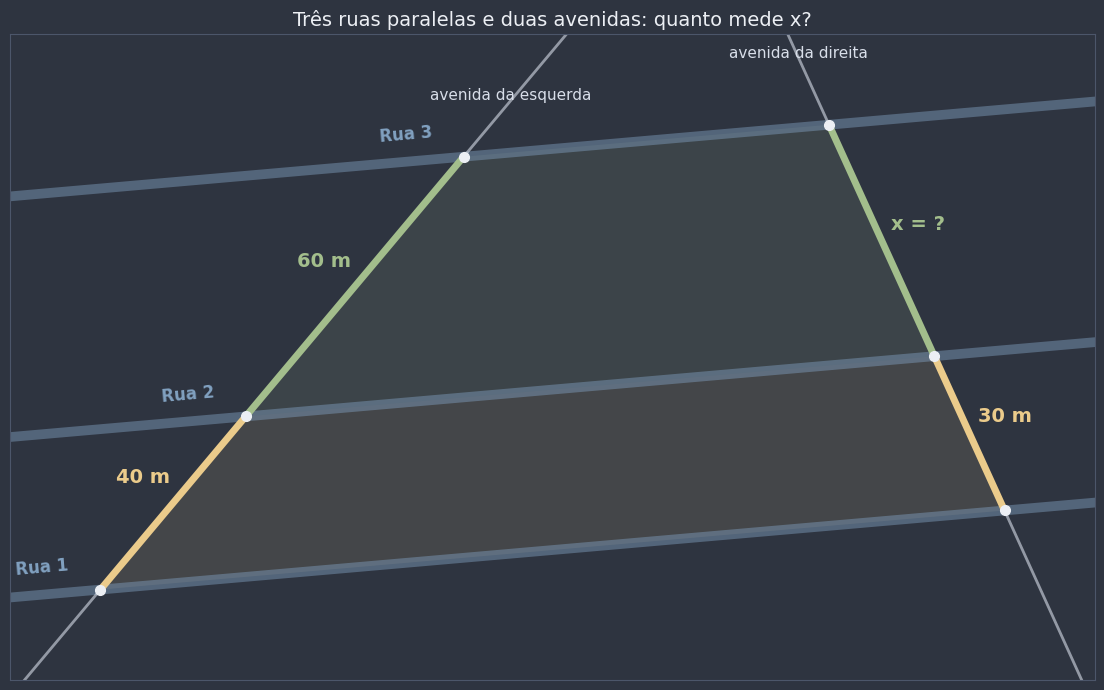

In [4]:
# Escala da figura: 1 unidade = 10 m
inclinacao_ruas = 5
inclinacao_esquerda = inclinacao_ruas + 45
pontos_esquerda = pontos_na_transversal((0, 0), inclinacao_esquerda, [4, 6])  # trechos de 40 m e 60 m
# A avenida da direita é inclinada de modo que o seu primeiro trecho meça exatamente 30 m (3 unidades);
# a conta (com seno, da Trigonometria) só serve para montar a figura
inclinacao_direita = inclinacao_ruas + 180 - math.degrees(math.asin(4 / 3 * math.sin(math.radians(45))))
inicio_direita = np.array([16.0, 16.0 * math.tan(math.radians(inclinacao_ruas))])  # um ponto da 1ª rua
pontos_direita = cortes_na_transversal(pontos_esquerda, inclinacao_ruas, inicio_direita, inclinacao_direita)

fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor(NORD_FUNDO)
preparar_eixo(ax, pontos_esquerda + pontos_direita, margem=1.6)
for k, cor in enumerate((COR_AVISO, COR_DESTAQUE)):  # os dois quarteirões, entre ruas vizinhas
    lote = [pontos_esquerda[k], pontos_direita[k], pontos_direita[k + 1], pontos_esquerda[k + 1]]
    ax.add_patch(Polygon(lote, closed=True, facecolor=cor, alpha=0.12, edgecolor="none", zorder=1))
for k, P in enumerate(pontos_esquerda):
    desenhar_reta(ax, P, pontos_direita[k], cor=COR_PARALELA, largura=7, alpha=0.45)
    ax.text(*(P + 1.0 * direcao(inclinacao_ruas + 180) + 0.35 * direcao(inclinacao_ruas + 90)), f"Rua {k + 1}",
            color=COR_PARALELA, fontsize=12, fontweight="bold", ha="center", rotation=inclinacao_ruas)
desenhar_reta(ax, pontos_esquerda[0], pontos_esquerda[-1], cor=COR_TRANSVERSAL, largura=2, alpha=0.6)
desenhar_reta(ax, pontos_direita[0], pontos_direita[-1], cor=COR_TRANSVERSAL, largura=2, alpha=0.6)
centro = np.mean(np.vstack(pontos_esquerda + pontos_direita), axis=0)
for k, (rotulo_esq, rotulo_dir) in enumerate((("40 m", "30 m"), ("60 m", "x = ?"))):
    for pontos, rotulo in ((pontos_esquerda, rotulo_esq), (pontos_direita, rotulo_dir)):
        desenhar_segmento(ax, pontos[k], pontos[k + 1], cor=CORES_PARES[k], largura=5)
        rotular_segmento(ax, pontos[k], pontos[k + 1], rotulo, cor=CORES_PARES[k], distancia=0.7, longe_de=centro,
                         tamanho=14)
for P in pontos_esquerda + pontos_direita:
    desenhar_ponto(ax, P, cor=NORD_TEXTO)
ax.text(*(pontos_esquerda[-1] + 1.3 * direcao(inclinacao_esquerda)), "avenida da esquerda", color=COR_TRANSVERSAL,
        fontsize=11, ha="center")
ax.text(*(pontos_direita[-1] + 1.3 * direcao(inclinacao_direita)), "avenida da direita", color=COR_TRANSVERSAL,
        fontsize=11, ha="center")
ax.set_title("Três ruas paralelas e duas avenidas: quanto mede x?", color=NORD_TEXTO, fontsize=14)
plt.tight_layout()
plt.show()

### O fio condutor deste notebook

Até aqui, o módulo trabalhou com **figuras e ângulos**. Este notebook abre uma nova fase: as **proporções entre segmentos**. Cada seção usa a anterior:

| Seção | A ideia em uma frase |
|---|---|
| 1. Razão e proporção | comparar segmentos por **divisão** ("quantas vezes um cabe no outro") e dividir um segmento numa razão dada |
| 2. Feixe de paralelas e o lema | paralelas que cortam pedaços **iguais** numa transversal cortam pedaços iguais em **qualquer** outra (o truque da folha pautada) |
| 3. Teorema de Tales | paralelas cortam as transversais em pedaços **proporcionais** (os lotes) |
| 4. Tales no triângulo | uma paralela a um lado divide os outros dois lados **na mesma razão** |
| 5. Bissetriz | a bissetriz divide o lado oposto **na razão dos lados adjacentes** |

No caminho, duas promessas antigas serão cumpridas: a razão $AP/PB$ dos desafios de [`0402a_segmento_de_reta.ipynb`](0402a_segmento_de_reta.ipynb) (seção 1) e a **demonstração** da razão 2 : 1 do baricentro, que em [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) foi obtida com coordenadas (Desafio 6).

## 1. Razão e proporção entre segmentos

Em [`0402a_segmento_de_reta.ipynb`](0402a_segmento_de_reta.ipynb), você comparou segmentos dizendo qual é **maior**, qual é **menor** ou se são **congruentes**. Agora a comparação fica mais fina: **quantas vezes** um segmento cabe no outro.

📌 **Definição formal (razão entre segmentos):** a **razão** entre os segmentos $\overline{AB}$ e $\overline{CD}$, nessa ordem, é o quociente das suas medidas, **tomadas na mesma unidade**:

$$\frac{AB}{CD}.$$

É um número **sem unidade**: se $AB = 6$ cm e $CD = 4$ cm, então $\dfrac{AB}{CD} = \dfrac{6 \text{ cm}}{4 \text{ cm}} = 1{,}5$, e os "cm" se cancelam. Por isso a razão não depende da unidade escolhida: em milímetros, $\dfrac{60 \text{ mm}}{40 \text{ mm}} = 1{,}5$ também.

📌 **Definição formal (segmentos proporcionais):** os segmentos de medidas $a$, $b$, $c$ e $d$, **nesta ordem**, são **proporcionais** quando a razão entre os dois primeiros é igual à razão entre os dois últimos:

$$\frac{a}{b} = \frac{c}{d} \iff a \cdot d = b \cdot c.$$

Na proporção $\frac{a}{b} = \frac{c}{d}$, os números $a$ e $d$ são os **extremos** e $b$ e $c$ são os **meios**. Três propriedades serão usadas o tempo todo neste notebook:

| Propriedade | Se $\dfrac{a}{b} = \dfrac{c}{d}$, então... | Exemplo com $\dfrac{4}{6} = \dfrac{10}{15}$ |
|---|---|---|
| **Produto dos meios = produto dos extremos** | $a \cdot d = b \cdot c$ | $4 \cdot 15 = 60 = 6 \cdot 10$ |
| **Propriedade da soma** | $\dfrac{a + b}{b} = \dfrac{c + d}{d}$ (e também $\dfrac{a + b}{a} = \dfrac{c + d}{c}$) | $\dfrac{10}{6} = \dfrac{25}{15} = 1{,}666...$ |
| **Troca dos meios** ("alternando") | $\dfrac{a}{c} = \dfrac{b}{d}$ | $\dfrac{4}{10} = \dfrac{6}{15} = 0{,}4$ |

**Por que valem?** A primeira é multiplicar os dois lados de $\frac{a}{b} = \frac{c}{d}$ por $b \cdot d$. A da soma é somar 1 aos dois lados: $\frac{a}{b} + 1 = \frac{c}{d} + 1$, ou seja, $\frac{a + b}{b} = \frac{c + d}{d}$. A troca dos meios é dividir os dois lados de $a \cdot d = b \cdot c$ por $c \cdot d$.

**No código:** a função `razao` é só uma divisão; a função `sao_proporcionais` testa a proporção pelo **produto cruzado** $a \cdot d = b \cdot c$ (com a tolerância de `iguais`), que não tem problema com divisão por zero. A tabela confere as três propriedades em quatro quádruplas de segmentos.

In [5]:
def razao(a: float, b: float) -> float:
    """Razão entre dois segmentos de medidas a e b (na MESMA unidade): o quociente a / b, um número sem unidade."""
    return a / b


def sao_proporcionais(a: float, b: float, c: float, d: float) -> bool:
    """True se os segmentos a, b, c, d (nesta ordem) são proporcionais, a / b = c / d. O teste usa o produto
    dos extremos e dos meios (a·d = b·c), que dispensa a divisão."""
    return iguais(a * d, b * c)


quadruplas = [(4, 6, 10, 15), (4, 10, 6, 15), (3, 5, 4, 7), (2.5, 4, 5, 8)]
linhas = []
for a, b, c, d in quadruplas:
    linhas.append({"a, b, c, d": f"{a:g}, {b:g}, {c:g}, {d:g}", "a/b": f"{razao(a, b):.4f}",
                   "c/d": f"{razao(c, d):.4f}", "a·d": f"{a * d:g}", "b·c": f"{b * c:g}",
                   "proporcionais?": "sim" if sao_proporcionais(a, b, c, d) else "não",
                   "(a+b)/b": f"{razao(a + b, b):.4f}", "(c+d)/d": f"{razao(c + d, d):.4f}",
                   "a/c": f"{razao(a, c):.4f}", "b/d": f"{razao(b, d):.4f}"})
display(pd.DataFrame(linhas).style.hide(axis="index"))

"a, b, c, d",a/b,c/d,a·d,b·c,proporcionais?,(a+b)/b,(c+d)/d,a/c,b/d
"4, 6, 10, 15",0.6667,0.6667,60,60,sim,1.6667,1.6667,0.4000,0.4000
"4, 10, 6, 15",0.4000,0.4000,60,60,sim,1.4000,1.4000,0.6667,0.6667
"3, 5, 4, 7",0.6000,0.5714,21,20,não,1.6000,1.5714,0.7500,0.7143
"2.5, 4, 5, 8",0.6250,0.6250,20,20,sim,1.6250,1.6250,0.5000,0.5000


Nas linhas em que a quádrupla **é** proporcional, as colunas vêm em pares iguais: $a/b = c/d$, $(a+b)/b = (c+d)/d$ e $a/c = b/d$. Repare na segunda linha: $4, 10, 6, 15$ é a primeira quádrupla com os **meios trocados**, e continua proporcional. Na terceira, nada bate: $3 \cdot 7 = 21 \neq 20 = 5 \cdot 4$.

### Dividir um segmento numa razão dada

Os Desafios 5 e 6 de [`0402a_segmento_de_reta.ipynb`](0402a_segmento_de_reta.ipynb) fizeram a pergunta: onde fica o ponto $P$ do segmento $\overline{AB}$ tal que $AP / PB$ é um número dado? Agora ela ganha a forma definitiva.

Se $\dfrac{AP}{PB} = \dfrac{m}{n}$, imagine $\overline{AB}$ cortado em $m + n$ pedacinhos iguais: $\overline{AP}$ ocupa $m$ deles e $\overline{PB}$ ocupa os outros $n$. Então $P$ andou $\dfrac{m}{m + n}$ do caminho de $A$ até $B$, e isso vale para cada coordenada:

$$P = A + \frac{m}{m + n}\,(B - A).$$

- Razão $1 : 1$: $P = A + \frac{1}{2}(B - A)$, o **ponto médio** de [`0402a_segmento_de_reta.ipynb`](0402a_segmento_de_reta.ipynb).
- Razão $2 : 1$: $P$ fica a $\frac{2}{3}$ do caminho, exatamente a posição do **baricentro** em cada mediana ([`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb)).

**No código:** a função `divide_segmento(A, B, m, n)` aplica a fórmula. A tabela mede $AP$ e $PB$ com `math.dist` e confere a razão.

In [6]:
def divide_segmento(A, B, m: float, n: float) -> np.ndarray:
    """Ponto P do segmento AB tal que AP / PB = m / n: P anda m / (m + n) do caminho de A até B,
    coordenada a coordenada (é o Desafio 6 de 0402a, com a razão escrita como m : n)."""
    A, B = np.asarray(A, dtype=float), np.asarray(B, dtype=float)
    return A + m / (m + n) * (B - A)


A, B = np.array([1.0, 1.0]), np.array([9.0, 5.0])
linhas = []
for m, n in [(1, 1), (2, 1), (3, 5), (1, 3), (7, 2)]:
    P = divide_segmento(A, B, m, n)
    AP, PB = math.dist(A, P), math.dist(P, B)
    linhas.append({"razão pedida m : n": f"{m} : {n}", "fração do caminho m/(m+n)": f"{m / (m + n):.4f}",
                   "P": f"({P[0]:.3f}, {P[1]:.3f})", "AP": f"{AP:.4f}", "PB": f"{PB:.4f}",
                   "AP/PB (medido)": f"{AP / PB:.4f}", "m/n": f"{m / n:.4f}"})
display(pd.DataFrame(linhas).style.hide(axis="index"))

razão pedida m : n,fração do caminho m/(m+n),P,AP,PB,AP/PB (medido),m/n
1 : 1,0.5000,"(5.000, 3.000)",4.4721,4.4721,1.0000,1.0000
2 : 1,0.6667,"(6.333, 3.667)",5.9628,2.9814,2.0000,2.0000
3 : 5,0.3750,"(4.000, 2.500)",3.3541,5.5902,0.6000,0.6000
1 : 3,0.2500,"(3.000, 2.000)",2.2361,6.7082,0.3333,0.3333
7 : 2,0.7778,"(7.222, 4.111)",6.9567,1.9876,3.5000,3.5000


A representação gráfica: o segmento $\overline{AB}$ com os $m + n$ pedacinhos marcados. $\overline{AP}$ (amarelo) ocupa $m$ pedacinhos e $\overline{PB}$ (verde), os outros $n$.

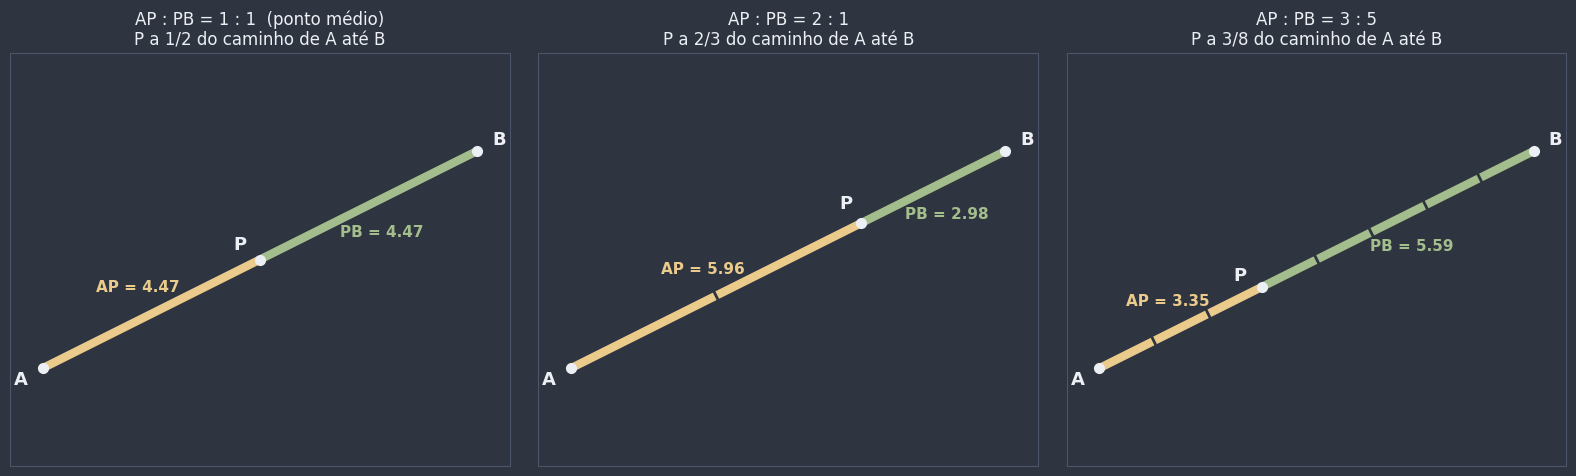

In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.6))
fig.patch.set_facecolor(NORD_FUNDO)
for ax, (m, n) in zip(eixos, [(1, 1), (2, 1), (3, 5)]):
    preparar_eixo(ax, [A, B, (1, 6.2), (9, -0.2)], margem=0.6)
    P = divide_segmento(A, B, m, n)
    desenhar_segmento(ax, A, P, cor=CORES_PARES[0], largura=6)
    desenhar_segmento(ax, P, B, cor=CORES_PARES[1], largura=6)
    for k in range(1, m + n):  # os m + n pedacinhos iguais
        X = divide_segmento(A, B, k, m + n - k)
        marcar_congruentes(ax, X, X + (B - A) * 1e-3, tracos=1, cor=NORD_FUNDO, tamanho=0.18)
    rotular_segmento(ax, A, P, f"AP = {math.dist(A, P):.2f}", cor=CORES_PARES[0], distancia=0.55, longe_de=(9, 0))
    rotular_segmento(ax, P, B, f"PB = {math.dist(P, B):.2f}", cor=CORES_PARES[1], distancia=0.55, longe_de=(1, 6))
    for X, nome in ((A, "A"), (B, "B"), (P, "P")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, (9, 0) if nome == "P" else (5, 3), distancia=0.45, tamanho=13)
    extra = "  (ponto médio)" if m == n else ""
    ax.set_title(f"AP : PB = {m} : {n}{extra}\nP a {m}/{m + n} do caminho de A até B", color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo:** os sliders `m` e `n` escolhem a razão $m : n$. O ponto $P$ desliza sobre $\overline{AB}$ e o painel mostra $AP$, $PB$ e a razão medida. Tente: (1) $m = n$ (o ponto médio); (2) $m = 2$, $n = 1$ e depois $m = 4$, $n = 2$: o ponto muda?; (3) $m = 1$ e $n$ grande: para onde $P$ vai?

In [8]:
def explorar_divisao(m: int, n: int) -> None:
    A_w, B_w = np.array([0.0, 0.0]), np.array([10.0, 3.0])
    P_w = divide_segmento(A_w, B_w, m, n)
    AP, PB = math.dist(A_w, P_w), math.dist(P_w, B_w)
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.4, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    preparar_eixo(ax, [A_w, B_w, (0, 4.5), (10, -1.5)], margem=0.6)
    desenhar_segmento(ax, A_w, P_w, cor=CORES_PARES[0], largura=6)
    desenhar_segmento(ax, P_w, B_w, cor=CORES_PARES[1], largura=6)
    for k in range(1, m + n):
        X = divide_segmento(A_w, B_w, k, m + n - k)
        marcar_congruentes(ax, X, X + (B_w - A_w) * 1e-3, tracos=1, cor=NORD_FUNDO, tamanho=0.2)
    rotular_segmento(ax, A_w, P_w, f"{AP:.2f}", cor=CORES_PARES[0], distancia=0.5, longe_de=(10, -2))
    rotular_segmento(ax, P_w, B_w, f"{PB:.2f}", cor=CORES_PARES[1], distancia=0.5, longe_de=(0, 5))
    for X, nome in ((A_w, "A"), (B_w, "B"), (P_w, "P")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, (10, -2) if nome == "P" else (5, 1.5), distancia=0.5, tamanho=14)
    ax.set_title(f"AP : PB = {m} : {n}  →  {m + n} pedacinhos iguais", color=NORD_TEXTO, fontsize=13)
    itens = [
        (f"AP = {AP:.4f}   e   PB = {PB:.4f}", True),
        (f"AP/PB medido = {AP / PB:.4f}", True),
        (f"m/n = {m}/{n} = {m / n:.4f}", iguais(AP / PB, m / n)),
        (f"P anda {m}/{m + n} = {m / (m + n):.4f} do caminho de A até B", True),
        ("P é o ponto médio de AB (m = n)", m == n),
        ("P está mais perto de A (m < n)", m < n),
    ]
    escrever_checklist(ax_lista, itens, "Dividindo AB na razão m : n")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_divisao,
    m=widgets.IntSlider(value=2, min=1, max=10, step=1, description="m:"),
    n=widgets.IntSlider(value=1, min=1, max=10, step=1, description="n:"),
);

interactive(children=(IntSlider(value=2, description='m:', max=10, min=1), IntSlider(value=1, description='n:'…

Com $m = 2, n = 1$ e com $m = 4, n = 2$, o ponto $P$ é **o mesmo**: o que importa é a razão $\frac{m}{n}$, e $\frac{2}{1} = \frac{4}{2}$.

💡 **Dica:** a razão $1 : 1$ é o ponto médio, e a razão $2 : 1$ (a $\frac{2}{3}$ do caminho) é a do baricentro, que vai aparecer de novo no desafio final deste notebook. Atenção à **ordem**: "$AP : PB = 2 : 1$" é contado **a partir de $A$**; trocar para $1 : 2$ joga o ponto para o outro terço do segmento.

⚠️ **Erro comum:** calcular a razão entre segmentos medidos em **unidades diferentes**. Se $AB = 50$ cm e $CD = 2$ m, a razão **não** é $\frac{50}{2} = 25$: convertendo tudo para centímetros, $\frac{AB}{CD} = \frac{50}{200} = \frac{1}{4}$. Antes de dividir, coloque as duas medidas na mesma unidade.

🎯 **Aplicação prática — receitas e misturas:** "3 partes de areia para 1 de cimento" é uma razão sem unidade: vale com baldes, com pás ou com caminhões. É a mesma ideia de dividir um segmento na razão $3 : 1$: do total, $\frac{3}{4}$ é areia e $\frac{1}{4}$ é cimento.

**Pergunta de checagem:** os segmentos de 6 cm, 9 cm, 10 cm e 15 cm, nessa ordem, são proporcionais? E se a ordem for 6, 10, 9, 15?

**Pergunta de checagem:** um segmento $\overline{AB}$ mede 20 cm. O ponto $P$ de $\overline{AB}$ é tal que $AP : PB = 3 : 2$. Quanto medem $AP$ e $PB$?

## 2. Feixe de paralelas e o lema dos segmentos congruentes

📌 **Definição formal (feixe de paralelas e transversal):** um **feixe de retas paralelas** é um conjunto de retas de um plano, todas paralelas entre si. Uma **transversal** do feixe é uma reta do mesmo plano que corta **todas** as retas do feixe (como em [`0406a_paralelismo.ipynb`](0406a_paralelismo.ipynb), em que uma transversal cortava duas paralelas).

As linhas do caderno formam um feixe de paralelas; a tira de papel e o "caminho reto para cima" são duas transversais. O truque do gancho é o caso particular mais simples do teorema deste notebook, e vale a pena prová-lo primeiro.

📌 **Lema (segmentos congruentes):** se três ou mais retas paralelas determinam segmentos **congruentes** sobre uma transversal, então elas determinam segmentos **congruentes** sobre **qualquer** outra transversal.

### Demonstração

Sejam $a$, $b$ e $c$ três retas paralelas. A transversal $t$ as corta em $A$, $B$ e $C$, com $\overline{AB} \equiv \overline{BC}$; outra transversal $t'$ as corta em $A'$, $B'$ e $C'$. Queremos provar que $\overline{A'B'} \equiv \overline{B'C'}$.

A ideia é **transportar** os segmentos de $t$ até $t'$. Por $A'$, trace a reta paralela a $t$; ela corta $b$ no ponto $X$. Por $B'$, trace a paralela a $t$; ela corta $c$ no ponto $Y$.

| Passo | Afirmação | Justificativa |
|---|---|---|
| 1 | $ABXA'$ é um paralelogramo | $\overline{AA'}$ e $\overline{BX}$ estão em $a$ e $b$, que são paralelas; $\overline{AB}$ e $\overline{A'X}$ estão em $t$ e numa paralela a $t$ |
| 2 | $A'X = AB$ | lados opostos de um paralelogramo são congruentes ([`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb)) |
| 3 | $B'Y = BC$ | o mesmo raciocínio no paralelogramo $BCYB'$ |
| 4 | $A'X = B'Y$ | passos 2 e 3, e a hipótese $AB = BC$ |
| 5 | $X\hat{A'}B' \equiv Y\hat{B'}C'$ | ângulos **correspondentes**: $\overleftrightarrow{A'X} \parallel \overleftrightarrow{B'Y}$ (ambas paralelas a $t$), cortadas pela transversal $t'$ ([`0406a_paralelismo.ipynb`](0406a_paralelismo.ipynb)) |
| 6 | $A'\hat{X}B' \equiv B'\hat{Y}C'$ | os dois têm lados paralelos ($\overline{XA'} \parallel \overline{YB'}$ e $\overline{XB'} \parallel \overline{YC'}$) e a mesma abertura: ambos são congruentes ao ângulo que $t$ forma com as retas do feixe (correspondentes, duas vezes) |
| 7 | $\triangle A'XB' \equiv \triangle B'YC'$ | caso **ALA** (passos 5, 4 e 6: o lado $\overline{A'X}$ fica entre os dois ângulos) ([`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb)) |
| 8 | $A'B' = B'C'$ | lados correspondentes de triângulos congruentes ∎ |

Com mais de três paralelas, basta repetir o argumento de duas em duas. (Se $t'$ for paralela a $t$, os próprios $ABB'A'$ e $BCC'B'$ já são paralelogramos, e o resultado é imediato.)

A figura mostra a construção: os dois paralelogramos sombreados em azul transportam $\overline{AB}$ e $\overline{BC}$ até $t'$, e os dois triângulos congruentes, em roxo, fazem o resto.

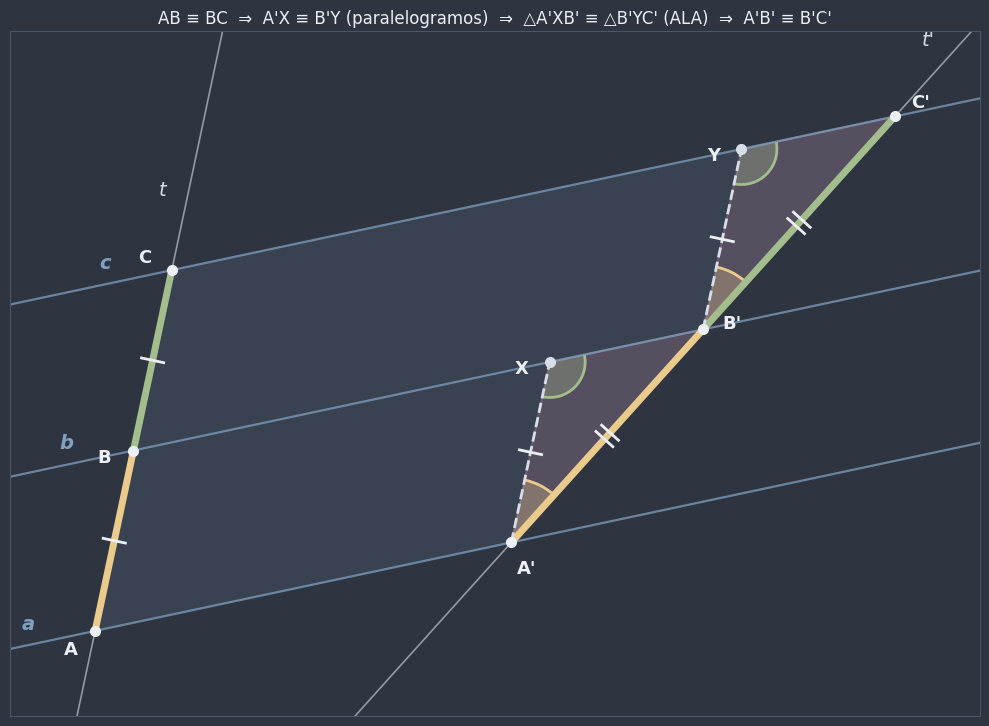

AB = 2.6000   BC = 2.6000
A'X = 2.6000   B'Y = 2.6000
A'B' = 4.0410   B'C' = 4.0410


In [9]:
inclinacao_feixe_l = 12
A_l = np.array([0.0, 0.0])
pontos_t_l = pontos_na_transversal(A_l, 78, [2.6, 2.6])  # A, B, C com AB = BC
A2_l = A_l + 6.0 * direcao(inclinacao_feixe_l)  # A', na reta a
pontos_t2_l = cortes_na_transversal(pontos_t_l, inclinacao_feixe_l, A2_l, 48)  # A', B', C' na transversal t'
(A_, B_, C_), (A2_, B2_, C2_) = pontos_t_l, pontos_t2_l
X_l = cruzamento(A2_, 78, B_, inclinacao_feixe_l)  # paralela a t por A', cortando b
Y_l = cruzamento(B2_, 78, C_, inclinacao_feixe_l)  # paralela a t por B', cortando c

fig, ax = plt.subplots(figsize=(10, 7.5))
fig.patch.set_facecolor(NORD_FUNDO)
preparar_eixo(ax, pontos_t_l + pontos_t2_l + [X_l, Y_l], margem=1.2)
for P, Q, R, S_ in ((A_, B_, X_l, A2_), (B_, C_, Y_l, B2_)):  # os dois paralelogramos
    ax.add_patch(Polygon([P, Q, R, S_], closed=True, facecolor=COR_PARALELA, alpha=0.13, edgecolor="none"))
for P, Q, R in ((A2_, X_l, B2_), (B2_, Y_l, C2_)):  # os dois triângulos congruentes
    ax.add_patch(Polygon([P, Q, R], closed=True, facecolor=COR_EXTRA, alpha=0.3, edgecolor=COR_EXTRA, lw=1.5))
desenhar_feixe(ax, pontos_t_l, pontos_t2_l, rotular_medidas=False)
for P, Q in ((A2_, X_l), (B2_, Y_l)):
    desenhar_segmento(ax, P, Q, cor=NORD_TEXTO_SEC, largura=2, estilo="--")
for P, Q in ((A_, B_), (B_, C_), (A2_, X_l), (B2_, Y_l)):
    marcar_congruentes(ax, P, Q, tracos=1)
for P, Q in ((A2_, B2_), (B2_, C2_)):
    marcar_congruentes(ax, P, Q, tracos=2)
desenhar_arco(ax, A2_, X_l, B2_, raio=0.9, cor=COR_AVISO)
desenhar_arco(ax, B2_, Y_l, C2_, raio=0.9, cor=COR_AVISO)
desenhar_arco(ax, X_l, A2_, B2_, raio=0.5, cor=COR_DESTAQUE)
desenhar_arco(ax, Y_l, B2_, C2_, raio=0.5, cor=COR_DESTAQUE)
for P, nome in ((X_l, "X"), (Y_l, "Y")):
    desenhar_ponto(ax, P, cor=NORD_TEXTO_SEC)
    rotular_fora(ax, P, nome, P + direcao(inclinacao_feixe_l), distancia=0.4, tamanho=13)
for P, nome in zip(pontos_t_l, "abc"):
    ax.text(*(P - 0.9 * direcao(inclinacao_feixe_l) + 0.3 * direcao(inclinacao_feixe_l + 90)), nome, color=COR_PARALELA, fontsize=14, fontweight="bold",
            ha="center", va="center", style="italic")
ax.text(*(C_ + 1.0 * direcao(78) + 0.4 * direcao(168)), "t", color=COR_TRANSVERSAL, fontsize=14, style="italic")
ax.text(*(C2_ + 1.0 * direcao(48) + 0.4 * direcao(138)), "t'", color=COR_TRANSVERSAL, fontsize=14, style="italic")
ax.set_title("AB ≡ BC  ⇒  A'X ≡ B'Y (paralelogramos)  ⇒  △A'XB' ≡ △B'YC' (ALA)  ⇒  A'B' ≡ B'C'",
             color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()
print(f"AB = {math.dist(A_, B_):.4f}   BC = {math.dist(B_, C_):.4f}")
print(f"A'X = {math.dist(A2_, X_l):.4f}   B'Y = {math.dist(B2_, Y_l):.4f}")
print(f"A'B' = {math.dist(A2_, B2_):.4f}   B'C' = {math.dist(B2_, C2_):.4f}")

### Aplicação direta: dividir um segmento em $n$ partes iguais (com régua e compasso)

O lema transforma o truque da folha pautada numa **construção** que funciona para qualquer segmento $\overline{AB}$, sem medir nada:

1. Por $A$, trace uma **semirreta auxiliar** qualquer (que não esteja sobre $\overline{AB}$).
2. Com o compasso numa abertura qualquer, marque nela $n$ pontos **igualmente espaçados** a partir de $A$: $Q_1, Q_2, \ldots, Q_n$.
3. Ligue o último ponto, $Q_n$, ao ponto $B$.
4. Por $Q_1, Q_2, \ldots, Q_{n-1}$, trace **paralelas** a $\overline{Q_nB}$. Elas cortam $\overline{AB}$ nos pontos de divisão.

**Por quê?** As paralelas (junto com a paralela que passa por $A$) formam um feixe que corta a semirreta auxiliar em pedaços congruentes (marcados com o compasso). Pelo lema, cortam $\overline{AB}$, a outra transversal, também em pedaços congruentes.

**No código:** a função `dividir_por_paralelas(A, B, n, angulo_auxiliar)` faz exatamente os passos da construção, usando `cruzamento` para achar onde cada paralela corta a reta $AB$. A tabela compara os pontos obtidos pela construção com os da fórmula da seção 1, `divide_segmento(A, B, k, n − k)`, para várias aberturas da semirreta auxiliar.

In [10]:
def dividir_por_paralelas(A, B, n: int, angulo_auxiliar: float = 35, passo: float = 1.0):
    """Divide AB em n partes iguais pela construção com régua e compasso, SEM medir AB:
    1) traça por A uma semirreta auxiliar, girada `angulo_auxiliar` graus em relação a AB;
    2) marca nela, com o compasso de abertura `passo`, n pontos igualmente espaçados: Q1, Q2, ..., Qn;
    3) liga Qn a B e traça, por Q1, ..., Q(n−1), paralelas a QnB: elas cortam AB nos pontos de divisão.
    Devolve (pontos de divisão sobre AB, pontos Q da semirreta auxiliar)."""
    A, B = np.asarray(A, dtype=float), np.asarray(B, dtype=float)
    direcao_auxiliar = direcao_de(A, B) + angulo_auxiliar
    Q = [A + k * passo * direcao(direcao_auxiliar) for k in range(1, n + 1)]
    inclinacao_paralelas = direcao_de(Q[-1], B)  # todas as paralelas têm a direção de QnB
    divisoes = [cruzamento(Q[k], inclinacao_paralelas, A, direcao_de(A, B)) for k in range(n - 1)]
    return divisoes, Q


A, B = np.array([0.0, 0.0]), np.array([9.0, 2.0])
n = 5
linhas = []
for angulo in [20, 45, 90, 140]:
    divisoes, _ = dividir_por_paralelas(A, B, n, angulo)
    pontos = [A] + divisoes + [B]
    pedacos = [math.dist(pontos[k], pontos[k + 1]) for k in range(n)]
    diferenca = max(math.dist(X, divide_segmento(A, B, k + 1, n - k - 1)) for k, X in enumerate(divisoes))
    linhas.append({"ângulo da semirreta auxiliar": f"{angulo}°",
                   "pedaços de AB (construção)": ", ".join(f"{p:.4f}" for p in pedacos),
                   "AB ÷ 5": f"{math.dist(A, B) / n:.4f}",
                   "maior distância até a fórmula": f"{diferenca:.1e}"})
display(pd.DataFrame(linhas).style.hide(axis="index"))

ângulo da semirreta auxiliar,pedaços de AB (construção),AB ÷ 5,maior distância até a fórmula
20°,"1.8439, 1.8439, 1.8439, 1.8439, 1.8439",1.8439,9.2e-16
45°,"1.8439, 1.8439, 1.8439, 1.8439, 1.8439",1.8439,1.8e-15
90°,"1.8439, 1.8439, 1.8439, 1.8439, 1.8439",1.8439,1.8e-15
140°,"1.8439, 1.8439, 1.8439, 1.8439, 1.8439",1.8439,9.2e-16


A semirreta auxiliar mudou de direção quatro vezes, e os pontos de divisão não saíram do lugar: a construção e a fórmula dão os mesmos pontos (a diferença é só arredondamento do computador, da ordem de $10^{-15}$). A figura mostra a construção para $n = 7$, o mesmo número do gancho: os traços auxiliares em cinza, as paralelas em azul.

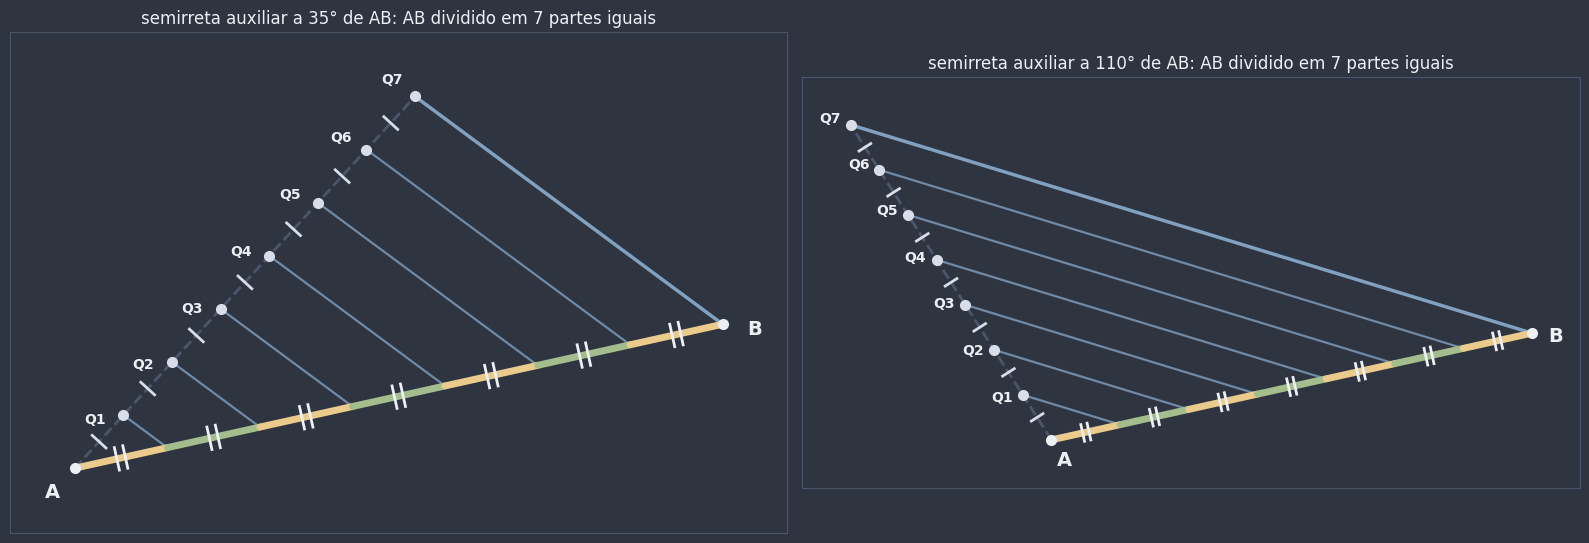

In [11]:
fig, eixos = plt.subplots(1, 2, figsize=(16, 6.4))
fig.patch.set_facecolor(NORD_FUNDO)
for ax, angulo in zip(eixos, (35, 110)):
    divisoes, Q = dividir_por_paralelas(A, B, 7, angulo)
    preparar_eixo(ax, [A, B] + Q, margem=0.9)
    desenhar_segmento(ax, A, Q[-1], cor=COR_AUXILIAR, largura=2, estilo="--")  # a semirreta auxiliar
    for k in range(7):
        anterior = A if k == 0 else Q[k - 1]
        marcar_congruentes(ax, anterior, Q[k], tracos=1, cor=NORD_TEXTO_SEC, tamanho=0.13)
        desenhar_ponto(ax, Q[k], cor=NORD_TEXTO_SEC)
        rotular_fora(ax, Q[k], f"Q{k + 1}", B, distancia=0.4, tamanho=10)
    desenhar_segmento(ax, Q[-1], B, cor=COR_PARALELA, largura=2.5)
    for X, Qk in zip(divisoes, Q):
        desenhar_segmento(ax, Qk, X, cor=COR_PARALELA, largura=1.6, alpha=0.8)
    pontos = [A] + divisoes + [B]
    for k in range(7):
        desenhar_segmento(ax, pontos[k], pontos[k + 1], cor=CORES_PARES[k % 2], largura=5)
        marcar_congruentes(ax, pontos[k], pontos[k + 1], tracos=2, tamanho=0.16)
    for X, nome in ((A, "A"), (B, "B")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, np.mean(Q, axis=0), distancia=0.45, tamanho=14)
    ax.set_title(f"semirreta auxiliar a {angulo}° de AB: AB dividido em 7 partes iguais", color=NORD_TEXTO,
                 fontsize=12)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo:** o slider `n` escolhe em quantas partes $\overline{AB}$ será dividido, o slider `ângulo` gira a semirreta auxiliar e o slider `compasso` muda a abertura do compasso (o espaçamento dos pontos $Q_k$). A construção é refeita a cada mudança. Observe o painel: os pontos de divisão sobre $\overline{AB}$ **não dependem** nem do ângulo nem da abertura escolhidos.

In [ ]:
def explorar_construcao(n: int, angulo: int, compasso: float) -> None:
    A_w, B_w = np.array([0.0, 0.0]), np.array([9.0, 2.0])
    divisoes, Q = dividir_por_paralelas(A_w, B_w, n, angulo, passo=compasso)
    pontos = [A_w] + divisoes + [B_w]
    pedacos = [math.dist(pontos[k], pontos[k + 1]) for k in range(n)]
    diferenca = max(math.dist(X, divide_segmento(A_w, B_w, k + 1, n - k - 1)) for k, X in enumerate(divisoes))

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(14, 6.4), gridspec_kw={"width_ratios": [1.35, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    preparar_eixo(ax, [A_w, B_w, (-1, -1), (10, 3)] + Q, margem=0.7)
    desenhar_segmento(ax, A_w, Q[-1], cor=COR_AUXILIAR, largura=2, estilo="--")
    for k in range(n):
        marcar_congruentes(ax, A_w if k == 0 else Q[k - 1], Q[k], tracos=1, cor=NORD_TEXTO_SEC, tamanho=0.12)
        desenhar_ponto(ax, Q[k], cor=NORD_TEXTO_SEC)
    desenhar_segmento(ax, Q[-1], B_w, cor=COR_PARALELA, largura=2.5)
    for X, Qk in zip(divisoes, Q):
        desenhar_segmento(ax, Qk, X, cor=COR_PARALELA, largura=1.5, alpha=0.8)
    for k in range(n):
        desenhar_segmento(ax, pontos[k], pontos[k + 1], cor=CORES_PARES[k % 2], largura=5)
    for X, nome in ((A_w, "A"), (B_w, "B")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, np.mean(Q, axis=0), distancia=0.45, tamanho=14)
    ax.set_title(f"AB em {n} partes: semirreta a {angulo}°, compasso {compasso:g}", color=NORD_TEXTO, fontsize=13)
    itens = [
        (f"AB = {math.dist(A_w, B_w):.4f};  AB ÷ {n} = {math.dist(A_w, B_w) / n:.4f}", True),
        (f"menor pedaço = {min(pedacos):.4f};  maior pedaço = {max(pedacos):.4f}", iguais(min(pedacos), max(pedacos))),
        (f"distância até os pontos da fórmula: {diferenca:.1e}", diferenca < 1e-9),
        ("o resultado não depende do ângulo nem do compasso", diferenca < 1e-9),
    ]
    escrever_checklist(ax_lista, itens, "Construção × fórmula")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_construcao,
    n=widgets.IntSlider(value=5, min=2, max=12, step=1, description="n:"),
    angulo=widgets.IntSlider(value=40, min=10, max=170, step=5, description="ângulo:"),
    compasso=widgets.FloatSlider(value=1.0, min=0.4, max=1.6, step=0.1, description="compasso:"),
);

interactive(children=(IntSlider(value=5, description='n:', max=12, min=2), IntSlider(value=40, description='ân…

📎 **Conexão:** a **base média do triângulo** ([`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb)) é o caso mais simples deste lema. No triângulo $ABC$, com $M$ ponto médio de $\overline{AB}$, a paralela a $\overline{BC}$ por $M$, junto com $\overline{BC}$ e a paralela a $\overline{BC}$ que passa por $A$, formam três paralelas que cortam $\overline{AB}$ em dois pedaços congruentes. Então cortam $\overline{AC}$ também em dois pedaços congruentes: **a paralela por um ponto médio passa pelo ponto médio do outro lado**.

🎯 **Aplicação prática — dividir sem régua graduada:** carpinteiros, costureiras e desenhistas técnicos usam a construção da folha pautada para dividir uma tábua, um tecido ou um desenho em partes iguais com um esquadro e um ponto de apoio, e programas de CAD usam o mesmo princípio para espaçar pontos igualmente ao longo de uma linha.

**Pergunta de checagem:** três retas paralelas cortam uma transversal em dois segmentos de 4 cm cada. Numa outra transversal, um dos segmentos determinados por elas mede 5 cm. Quanto mede o outro?

**Pergunta de checagem:** na construção, por que **não** precisamos medir $\overline{AB}$, nem escolher uma abertura especial do compasso?

## 3. O Teorema de Tales

O lema trata só de pedaços **iguais**. E se as paralelas cortarem a primeira transversal em pedaços diferentes, como os 40 m e 60 m dos lotes?

📌 **Teorema de Tales:** um **feixe de retas paralelas**, cortado por duas transversais, determina sobre elas **segmentos proporcionais**. Se as paralelas $a$, $b$ e $c$ cortam a transversal $t$ em $A$, $B$, $C$ e a transversal $t'$ em $A'$, $B'$, $C'$, então

$$\frac{AB}{BC} = \frac{A'B'}{B'C'} \qquad \text{e, trocando os meios,} \qquad \frac{AB}{A'B'} = \frac{BC}{B'C'}.$$

Com mais de três paralelas, vale a mesma coisa para **quaisquer** dois segmentos correspondentes (por exemplo, $\frac{AB}{CD} = \frac{A'B'}{C'D'}$), e também para segmentos formados por pedaços consecutivos, como $\frac{AC}{A'C'} = \frac{AB}{A'B'}$ (propriedade da soma).

A segunda forma diz algo bonito: o "fator de conversão" de $t$ para $t'$ é **o mesmo** para todos os segmentos. Se $A'B'$ é 1,5 vez $AB$, então $B'C'$ também é 1,5 vez $BC$.

### Demonstração (caso comensurável)

A ideia é a mesma da folha pautada. Suponha que exista um segmento de medida $u$ que cabe um **número inteiro** de vezes tanto em $\overline{AB}$ quanto em $\overline{BC}$: $AB = m \cdot u$ e $BC = n \cdot u$ (com $m$ e $n$ inteiros). Dois segmentos assim são chamados **comensuráveis** (têm uma "medida comum").

1. Divida $\overline{AB}$ em $m$ pedaços e $\overline{BC}$ em $n$ pedaços, todos de medida $u$.
2. Por cada ponto de divisão, trace uma paralela às retas do feixe. Agora há um feixe maior que corta $t$ em $m + n$ pedaços **congruentes**.
3. Pelo **lema** da seção 2, esse feixe corta $t'$ também em $m + n$ pedaços congruentes, de uma medida $u'$. Então $A'B' = m \cdot u'$ e $B'C' = n \cdot u'$.
4. Logo $\dfrac{A'B'}{B'C'} = \dfrac{m \cdot u'}{n \cdot u'} = \dfrac{m}{n} = \dfrac{m \cdot u}{n \cdot u} = \dfrac{AB}{BC}$. ∎

A figura mostra o caso $m = 2$ e $n = 3$: as paralelas auxiliares (tracejadas) dividem $t$ em pedaços de medida $u$ (um tracinho) e $t'$ em pedaços de medida $u'$ (dois tracinhos).

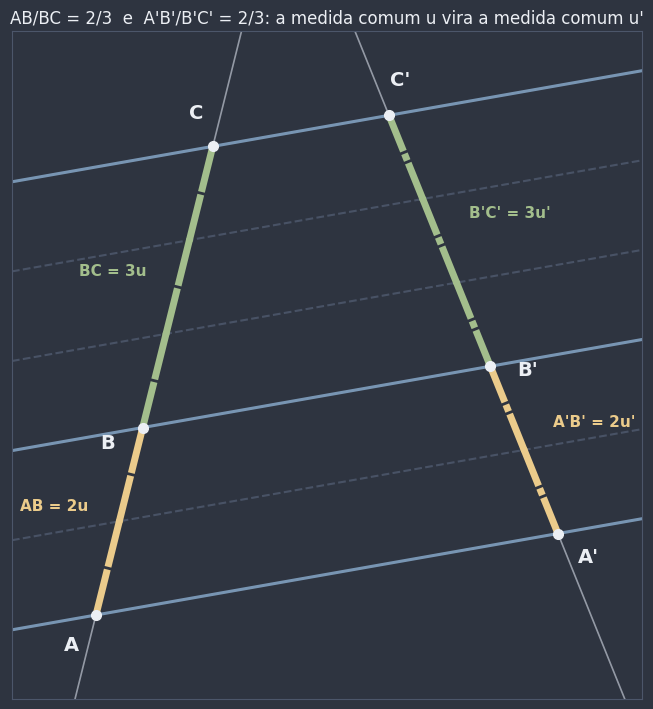

u = 1.1500   u' = 1.0740
AB/BC = 0.6667   A'B'/B'C' = 0.6667


In [13]:
u = 1.15
pontos_t_d = pontos_na_transversal((0, 0), 76, [u] * 5)  # A, os 4 pontos de divisão e C
pontos_t2_d = cortes_na_transversal(pontos_t_d, 10, np.array([5.5, 5.5 * math.tan(math.radians(10))]), 112)
principais = [0, 2, 5]  # A, B (= 2u) e C (= 2u + 3u)

fig, ax = plt.subplots(figsize=(10, 7.2))
fig.patch.set_facecolor(NORD_FUNDO)
preparar_eixo(ax, pontos_t_d + pontos_t2_d, margem=1.0)
for k, (P, P2) in enumerate(zip(pontos_t_d, pontos_t2_d)):
    if k in principais:
        desenhar_reta(ax, P, P2, cor=COR_PARALELA, largura=2.2)
    else:
        desenhar_reta(ax, P, P2, cor=COR_AUXILIAR, largura=1.5, estilo="--")
desenhar_reta(ax, pontos_t_d[0], pontos_t_d[-1], cor=COR_TRANSVERSAL, largura=1.2, alpha=0.6)
desenhar_reta(ax, pontos_t2_d[0], pontos_t2_d[-1], cor=COR_TRANSVERSAL, largura=1.2, alpha=0.6)
for k in range(5):
    cor = CORES_PARES[0] if k < 2 else CORES_PARES[1]
    for pontos, tracos in ((pontos_t_d, 1), (pontos_t2_d, 2)):
        desenhar_segmento(ax, pontos[k], pontos[k + 1], cor=cor, largura=5)
        marcar_congruentes(ax, pontos[k], pontos[k + 1], tracos=tracos, cor=NORD_FUNDO, tamanho=0.17)
centro = np.mean(np.vstack(pontos_t_d + pontos_t2_d), axis=0)
for k, nome in zip(principais, "ABC"):
    for X, rotulo in ((pontos_t_d[k], nome), (pontos_t2_d[k], nome + "'")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, rotulo, centro, distancia=0.45, tamanho=14)
rotular_segmento(ax, pontos_t_d[0], pontos_t_d[2], "AB = 2u", cor=CORES_PARES[0], distancia=0.8, longe_de=centro)
rotular_segmento(ax, pontos_t_d[2], pontos_t_d[5], "BC = 3u", cor=CORES_PARES[1], distancia=0.8, longe_de=centro)
rotular_segmento(ax, pontos_t2_d[0], pontos_t2_d[2], "A'B' = 2u'", cor=CORES_PARES[0], distancia=0.9,
                 longe_de=centro)
rotular_segmento(ax, pontos_t2_d[2], pontos_t2_d[5], "B'C' = 3u'", cor=CORES_PARES[1], distancia=0.9,
                 longe_de=centro)
ax.set_title("AB/BC = 2/3  e  A'B'/B'C' = 2/3: a medida comum u vira a medida comum u'", color=NORD_TEXTO,
             fontsize=12)
plt.tight_layout()
plt.show()
print(f"u = {math.dist(pontos_t_d[0], pontos_t_d[1]):.4f}   u' = {math.dist(pontos_t2_d[0], pontos_t2_d[1]):.4f}")
print(f"AB/BC = {math.dist(pontos_t_d[0], pontos_t_d[2]) / math.dist(pontos_t_d[2], pontos_t_d[5]):.4f}   "
      f"A'B'/B'C' = {math.dist(pontos_t2_d[0], pontos_t2_d[2]) / math.dist(pontos_t2_d[2], pontos_t2_d[5]):.4f}")

🕵️ **Curiosidade histórica — e se os segmentos não tiverem uma medida comum?** Os gregos acreditavam, no início, que quaisquer dois segmentos eram comensuráveis. Então descobriram que **não**: a diagonal e o lado de um quadrado, por exemplo, não têm nenhuma medida comum, por menor que seja (a razão entre eles é $\sqrt{2}$, um número **irracional**, como você viu em [`0103a_conjuntos_numericos.ipynb`](../01_conjuntos_e_funcoes/0103a_conjuntos_numericos.ipynb); essa diagonal volta em 📌 Triângulos Retângulos, com o Teorema de Pitágoras). A descoberta foi um choque para a escola pitagórica.

O Teorema de Tales **continua valendo** para segmentos incomensuráveis. A justificativa usa aproximações por razões de inteiros cada vez melhores ($\sqrt{2} \approx \frac{14}{10}, \frac{141}{100}, \frac{1414}{1000}, \ldots$), e cada uma delas cai no caso comensurável: é a ideia de **limite**, que você vai estudar no módulo de Cálculo. Neste notebook, o caso comensurável fica **demonstrado** e o caso irracional fica **verificado numericamente**, na tabela abaixo.

**No código:** a função `pontos_na_transversal` (definida na primeira célula) coloca os pontos $A, B, C, \ldots$ sobre $t$ com os espaçamentos dados; `cortes_na_transversal` traça por eles retas com a **mesma inclinação** (o feixe de paralelas) e calcula onde cada uma corta $t'$. A tabela compara as razões nas duas transversais, inclusive com espaçamentos irracionais como $\sqrt{2}$, $\pi$ e a razão áurea $\varphi = \frac{1 + \sqrt{5}}{2}$.

In [14]:
inclinacao_t, inclinacao_feixe, inclinacao_t2 = 80, 15, 62
inicio_t2 = np.array([4.0, 4.0 * math.tan(math.radians(inclinacao_feixe))])  # A', sobre a mesma reta do feixe que A

phi = (1 + math.sqrt(5)) / 2
casos = {"2 e 3": [2, 3], "1, 1 e 2": [1, 1, 2], "√2 e π": [math.sqrt(2), math.pi], "1 e φ": [1, phi],
         "√3, 1 e √5": [math.sqrt(3), 1, math.sqrt(5)]}
linhas = []
for nome, espacamentos in casos.items():
    pontos_t = pontos_na_transversal((0, 0), inclinacao_t, espacamentos)
    pontos_t2 = cortes_na_transversal(pontos_t, inclinacao_feixe, inicio_t2, inclinacao_t2)
    em_t = [math.dist(pontos_t[k], pontos_t[k + 1]) for k in range(len(espacamentos))]
    em_t2 = [math.dist(pontos_t2[k], pontos_t2[k + 1]) for k in range(len(espacamentos))]
    razoes_t = [em_t[k] / em_t[k + 1] for k in range(len(em_t) - 1)]
    razoes_t2 = [em_t2[k] / em_t2[k + 1] for k in range(len(em_t2) - 1)]
    fatores = [em_t2[k] / em_t[k] for k in range(len(em_t))]
    linhas.append({"espaçamentos em t": nome,
                   "segmentos em t'": ", ".join(f"{s:.4f}" for s in em_t2),
                   "razões consecutivas em t": ", ".join(f"{r:.10f}" for r in razoes_t),
                   "razões consecutivas em t'": ", ".join(f"{r:.10f}" for r in razoes_t2),
                   "fator t'/t de cada segmento": ", ".join(f"{f:.6f}" for f in fatores),
                   "maior diferença entre razões": f"{max(abs(r - s) for r, s in zip(razoes_t, razoes_t2)):.1e}"})
display(pd.DataFrame(linhas).style.hide(axis="index"))

espaçamentos em t,segmentos em t',razões consecutivas em t,razões consecutivas em t',fator t'/t de cada segmento,maior diferença entre razões
2 e 3,"2.4784, 3.7177",0.6666666667,0.6666666667,"1.239220, 1.239220",0.0e+00
"1, 1 e 2","1.2392, 1.2392, 2.4784","1.0000000000, 0.5000000000","1.0000000000, 0.5000000000","1.239220, 1.239220, 1.239220",6.7e-16
√2 e π,"1.7525, 3.8931",0.4501581581,0.4501581581,"1.239220, 1.239220",2.8e-16
1 e φ,"1.2392, 2.0051",0.6180339887,0.6180339887,"1.239220, 1.239220",3.3e-16
"√3, 1 e √5","2.1464, 1.2392, 2.7710","1.7320508076, 0.4472135955","1.7320508076, 0.4472135955","1.239220, 1.239220, 1.239220",1.3e-15


Em todas as linhas, as razões em $t$ e em $t'$ coincidem até a 10ª casa decimal (a diferença é do tamanho do arredondamento do computador), **inclusive com $\sqrt{2}$, $\pi$ e $\varphi$**. E a coluna do fator mostra a segunda forma do teorema: dentro de cada feixe, todos os segmentos de $t'$ são o **mesmo múltiplo** dos seus correspondentes em $t$ (aqui, as duas transversais e o feixe são os mesmos em todas as linhas, por isso o fator também é o mesmo).

Agora a representação gráfica, com quatro paralelas e as cores fixas deste notebook: cada par de segmentos **correspondentes** tem a sua cor (amarelo com amarelo, verde com verde, roxo com roxo), e os pontos têm nomes análogos nas duas transversais ($A$ e $A'$, $B$ e $B'$, ...).

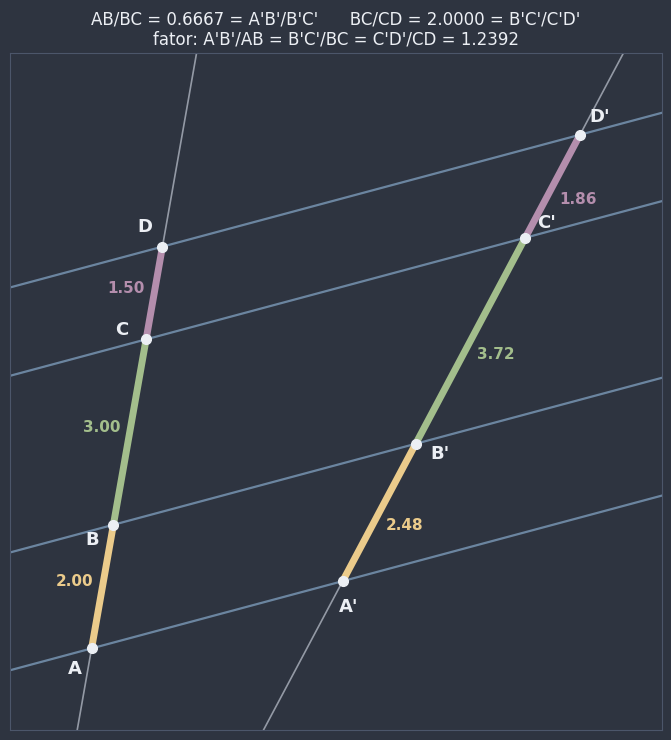

AB/BC = 0.666667     A'B'/B'C' = 0.666667
BC/CD = 2.000000     B'C'/C'D' = 2.000000
AB/CD = 1.333333     A'B'/C'D' = 1.333333   (segmentos não vizinhos também!)


In [15]:
pontos_t = pontos_na_transversal((0, 0), inclinacao_t, [2, 3, 1.5])
pontos_t2 = cortes_na_transversal(pontos_t, inclinacao_feixe, inicio_t2, inclinacao_t2)
AB, BC, CD = (math.dist(pontos_t[k], pontos_t[k + 1]) for k in range(3))
A2B2, B2C2, C2D2 = (math.dist(pontos_t2[k], pontos_t2[k + 1]) for k in range(3))

fig, ax = plt.subplots(figsize=(10, 7.5))
fig.patch.set_facecolor(NORD_FUNDO)
preparar_eixo(ax, pontos_t + pontos_t2, margem=1.3)
desenhar_feixe(ax, pontos_t, pontos_t2, nomes="ABCD")
ax.set_title(f"AB/BC = {AB / BC:.4f} = A'B'/B'C'      BC/CD = {BC / CD:.4f} = B'C'/C'D'\n"
             f"fator: A'B'/AB = B'C'/BC = C'D'/CD = {A2B2 / AB:.4f}", color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()
print(f"AB/BC = {AB / BC:.6f}     A'B'/B'C' = {A2B2 / B2C2:.6f}")
print(f"BC/CD = {BC / CD:.6f}     B'C'/C'D' = {B2C2 / C2D2:.6f}")
print(f"AB/CD = {AB / CD:.6f}     A'B'/C'D' = {A2B2 / C2D2:.6f}   (segmentos não vizinhos também!)")

### Os lotes do gancho, resolvidos

As três ruas são um feixe de paralelas e as duas avenidas são transversais. Pelo Teorema de Tales, os trechos correspondentes são proporcionais:

$$\frac{40}{60} = \frac{30}{x} \quad\Longrightarrow\quad 40\,x = 60 \cdot 30 \quad\Longrightarrow\quad x = \frac{1800}{40} = 45 \text{ m}.$$

(Na segunda passagem, o produto dos meios igual ao produto dos extremos, da seção 1.) A célula abaixo confere a conta medindo o trecho na própria figura do gancho.

In [16]:
x = 60 * 30 / 40  # pelo Teorema de Tales: 40/60 = 30/x
x_medido = 10 * math.dist(pontos_direita[1], pontos_direita[2])  # a figura do gancho está na escala 1 : 10
print(f"pela proporção: x = {x:.4f} m")
print(f"medido na figura: x = {x_medido:.4f} m")
print(f"conferência: 40/60 = {40 / 60:.6f}   e   30/x = {30 / x_medido:.6f}")

pela proporção: x = 45.0000 m
medido na figura: x = 45.0000 m
conferência: 40/60 = 0.666667   e   30/x = 0.666667


🕹️ **Widget interativo:** o slider `feixe` inclina todas as paralelas ao mesmo tempo, o slider `t'` gira a segunda transversal (em torno de $A'$) e o slider `BC` muda a distância entre a segunda e a terceira paralelas, medida sobre $t$ ($AB$ fica fixo em 2). O painel mostra as razões $AB/BC$ e $A'B'/B'C'$ lado a lado. Incline tudo à vontade: elas não se separam. No fim do painel, compare também os segmentos **sobre as paralelas** ($AA'$, $BB'$ e $CC'$): eles **não** seguem a proporção (veja o ⚠️ logo depois do widget).

In [ ]:
def explorar_tales(feixe: int, transversal_2: int, BC_w: float) -> None:
    A_w = np.array([0.0, 0.0])
    pontos_t_w = pontos_na_transversal(A_w, 80, [2.0, BC_w])
    A2_w = A_w + 4.0 * direcao(feixe)  # A' fica na reta do feixe que passa por A
    pontos_t2_w = cortes_na_transversal(pontos_t_w, feixe, A2_w, transversal_2)
    AB_w, BC_m = (math.dist(pontos_t_w[k], pontos_t_w[k + 1]) for k in range(2))
    A2B2_w, B2C2_w = (math.dist(pontos_t2_w[k], pontos_t2_w[k + 1]) for k in range(2))
    sobre_paralelas = [math.dist(P, P2) for P, P2 in zip(pontos_t_w, pontos_t2_w)]

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(14, 6.6), gridspec_kw={"width_ratios": [1.2, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    preparar_eixo(ax, pontos_t_w + pontos_t2_w, margem=1.2)
    desenhar_feixe(ax, pontos_t_w, pontos_t2_w, nomes="ABC")
    for P, P2 in zip(pontos_t_w, pontos_t2_w):  # os segmentos SOBRE as paralelas, só para comparar
        desenhar_segmento(ax, P, P2, cor=NORD_TEXTO_SEC, largura=1.2, estilo=":", zorder=4)
    ax.set_title(f"AB/BC = {AB_w / BC_m:.4f}     A'B'/B'C' = {A2B2_w / B2C2_w:.4f}", color=NORD_TEXTO, fontsize=13)
    itens = [
        (f"AB = {AB_w:.3f},  BC = {BC_m:.3f}  →  AB/BC = {AB_w / BC_m:.4f}", True),
        (f"A'B' = {A2B2_w:.3f},  B'C' = {B2C2_w:.3f}  →  A'B'/B'C' = {A2B2_w / B2C2_w:.4f}",
         iguais(AB_w / BC_m, A2B2_w / B2C2_w)),
        (f"fator: A'B'/AB = {A2B2_w / AB_w:.4f}  e  B'C'/BC = {B2C2_w / BC_m:.4f}", iguais(A2B2_w / AB_w, B2C2_w / BC_m)),
        (f"AB = A'B'? (iguais, e não só proporcionais)", iguais(AB_w, A2B2_w)),
        (f"sobre as paralelas: AA' = {sobre_paralelas[0]:.2f}, BB' = {sobre_paralelas[1]:.2f}, "
         f"CC' = {sobre_paralelas[2]:.2f}", True),
        (f"AA'/BB' = AB/BC?  ({sobre_paralelas[0] / sobre_paralelas[1]:.4f} × {AB_w / BC_m:.4f})",
         iguais(sobre_paralelas[0] / sobre_paralelas[1], AB_w / BC_m)),
    ]
    escrever_checklist(ax_lista, itens, "Teorema de Tales")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_tales,
    feixe=widgets.IntSlider(value=15, min=-25, max=25, step=5, description="feixe:"),
    transversal_2=widgets.IntSlider(value=62, min=40, max=140, step=2, description="t':"),
    BC_w=widgets.FloatSlider(value=3.0, min=0.5, max=5.0, step=0.25, description="BC:"),
);

interactive(children=(IntSlider(value=15, description='feixe:', max=25, min=-25, step=5), IntSlider(value=62, …

⚠️ **Erros comuns:**
- **Aplicar o teorema a retas que não são paralelas.** O teorema exige um feixe de **paralelas**; se as "ruas" não forem paralelas, as razões nas avenidas deixam de ser iguais.
- **Escrever a proporção com os segmentos fora de ordem**, como $\frac{AB}{BC} = \frac{B'C'}{A'B'}$. Os segmentos correspondentes são os que ficam **entre as mesmas duas paralelas** (é para isso que servem as cores e as letras análogas: $\overline{AB}$ com $\overline{A'B'}$, $\overline{BC}$ com $\overline{B'C'}$).
- **Achar que segmentos correspondentes são iguais** ($AB = A'B'$): só a **razão** se conserva, e os comprimentos mudam pelo fator.
- **Usar os segmentos sobre as próprias paralelas** ($AA'$, $BB'$, $CC'$) na proporção. Eles não são "pedaços de uma transversal" e, em geral, **não** são proporcionais a $AB$ e $BC$ (confira no widget: o último item quase sempre fica vermelho).

🎯 **Aplicação prática — lotes, ruas e mapas:** as divisas de terrenos entre ruas paralelas seguem a proporcionalidade de Tales, como no gancho: se um lado de um quarteirão tem frentes de 12 m, 15 m e 18 m, as frentes correspondentes do outro lado estão na mesma razão $12 : 15 : 18$. E a **escala** de um mapa ($1 : 50\,000$) é exatamente uma razão entre segmentos, sem unidade.

🕵️ **Curiosidade histórica — um nome, dois teoremas:** o teorema é atribuído a **Tales de Mileto** (século VI a.C.), que, segundo uma lenda contada por Plutarco, teria medido a altura de uma pirâmide do Egito comparando a sombra dela com a sombra de um bastão. A literatura usa o nome "Teorema de Tales" para **dois** resultados diferentes: este, do feixe de paralelas (o uso mais comum no Brasil), e o do ângulo inscrito numa semicircunferência, que você viu em [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb). Neste curso, "Teorema de Tales" é sempre o das paralelas, e o outro é chamado pelo nome descritivo: **triângulo retângulo inscrito numa semicircunferência**.

📖 **Leitura complementar:** [Teorema de Tales (interseção)](https://pt.wikipedia.org/wiki/Teorema_de_Tales_(interse%C3%A7%C3%A3o)), [Tales de Mileto](https://pt.wikipedia.org/wiki/Tales_de_Mileto) e, só como referência cruzada, [Teorema de Tales (círculo)](https://pt.wikipedia.org/wiki/Teorema_de_Tales_(c%C3%ADrculo))

**Pergunta de checagem:** três paralelas cortam uma transversal em segmentos de 3 cm e 5 cm. Na outra transversal, o primeiro segmento mede 6 cm. Quanto mede o segundo?

**Pergunta de checagem:** num feixe de paralelas, $AB = 4$, $BC = 6$ e $A'C' = 15$ (o segmento inteiro, de $A'$ até $C'$). Quanto medem $A'B'$ e $B'C'$? (Dica: propriedade da soma.)

## 4. Tales no triângulo (paralela a um lado)

Este é o caso **mais usado** do teorema.

📌 **Teorema (Tales no triângulo):** num triângulo $ABC$, se uma reta **paralela ao lado $\overline{BC}$** corta os lados $\overline{AB}$ e $\overline{AC}$ nos pontos $D$ e $E$, então ela divide esses dois lados na mesma razão:

$$\frac{AD}{DB} = \frac{AE}{EC} \qquad \text{e também} \qquad \frac{AD}{AB} = \frac{AE}{AC}.$$

**Demonstração:** por $A$, trace a reta paralela a $\overline{BC}$. Agora há **três** paralelas: a que passa por $A$, a reta $DE$ e a reta $BC$. As retas $AB$ e $AC$ são duas transversais desse feixe, que corta a primeira em $A$, $D$, $B$ e a segunda em $A$, $E$, $C$. Pelo Teorema de Tales (seção 3), $\frac{AD}{DB} = \frac{AE}{EC}$. A segunda forma sai da **propriedade da soma** (seção 1): $\frac{AD + DB}{AD} = \frac{AE + EC}{AE}$, ou seja, $\frac{AB}{AD} = \frac{AC}{AE}$; invertendo os dois lados, $\frac{AD}{AB} = \frac{AE}{AC}$. ∎

(Aqui as duas transversais se cruzam em $A$, sobre a primeira paralela. Isso não atrapalha nada: o teorema só usa os pedaços de cada transversal entre paralelas vizinhas, $\overline{AD}$ e $\overline{DB}$ numa, $\overline{AE}$ e $\overline{EC}$ na outra.)

📌 **Recíproca (muito usada para provar paralelismo):** se $D$ está em $\overline{AB}$, $E$ está em $\overline{AC}$ e $\dfrac{AD}{DB} = \dfrac{AE}{EC}$, então $\overline{DE} \parallel \overline{BC}$.

**Por quê?** Trace por $D$ a paralela a $\overline{BC}$; ela corta $\overline{AC}$ num ponto $E'$. Pelo teorema, $\frac{AD}{DB} = \frac{AE'}{E'C}$. Então $\frac{AE'}{E'C} = \frac{AE}{EC}$: os pontos $E$ e $E'$ dividem $\overline{AC}$ na **mesma razão**. Mas, pela seção 1, só existe **um** ponto que divide um segmento numa razão dada ($P = A + \frac{m}{m+n}(C - A)$). Logo $E' = E$, e $\overline{DE}$ é a paralela. ∎

**No código:** a função `ponto_E_paralelo(A, B, C, D)` calcula $E$ pela segunda forma do teorema ($E$ anda, de $A$ até $C$, a mesma fração que $D$ andou de $A$ até $B$). Para conferir de forma **independente**, a função `sao_paralelos` (definida na primeira célula) testa o paralelismo de $\overline{DE}$ e $\overline{BC}$ pelo **produto vetorial** das direções, a "multiplicação cruzada" de [`0401a_nocoes_e_proposicoes_primitivas.ipynb`](0401a_nocoes_e_proposicoes_primitivas.ipynb): ele é zero exatamente quando as direções são paralelas.

In [18]:
def ponto_E_paralelo(A, B, C, D) -> np.ndarray:
    """Dado D no lado AB do triângulo ABC, o ponto E do lado AC tal que DE ∥ BC. Pela 2ª forma de Tales
    no triângulo, AE / AC = AD / AB: E anda, de A até C, a mesma fração que D andou de A até B."""
    fracao = math.dist(A, D) / math.dist(A, B)
    return np.asarray(A, dtype=float) + fracao * (np.asarray(C, dtype=float) - np.asarray(A, dtype=float))


A, B, C = np.array([2.0, 6.0]), np.array([0.0, 0.0]), np.array([8.0, 0.0])
linhas = []
for fracao in [0.2, 0.4, 0.5, 0.75]:
    D = A + fracao * (B - A)  # D anda essa fração de A até B
    E = ponto_E_paralelo(A, B, C, D)
    AD, DB, AE, EC = math.dist(A, D), math.dist(D, B), math.dist(A, E), math.dist(E, C)
    linhas.append({"D anda de A até B": f"{fracao:.0%}", "AD/DB": f"{AD / DB:.4f}", "AE/EC": f"{AE / EC:.4f}",
                   "AD/AB": f"{AD / math.dist(A, B):.4f}", "AE/AC": f"{AE / math.dist(A, C):.4f}",
                   "produto vetorial (DE, BC)": f"{produto_vetorial(E - D, C - B):.1e}",
                   "DE ∥ BC?": "sim" if sao_paralelos(D, E, B, C) else "não"})
display(pd.DataFrame(linhas).style.hide(axis="index"))

D anda de A até B,AD/DB,AE/EC,AD/AB,AE/AC,"produto vetorial (DE, BC)",DE ∥ BC?
20%,0.2500,0.2500,0.2000,0.2000,0.0e+00,sim
40%,0.6667,0.6667,0.4000,0.4000,0.0e+00,sim
50%,1.0000,1.0000,0.5000,0.5000,0.0e+00,sim
75%,3.0000,3.0000,0.7500,0.7500,0.0e+00,sim


Agora o caminho inverso, a **recíproca**: escolhemos $D$ e $E$ diretamente pelas razões e perguntamos se $\overline{DE}$ é paralelo a $\overline{BC}$. Só dá "sim" quando as duas razões coincidem.

In [19]:
linhas = []
for (m_D, n_D), (m_E, n_E) in [((2, 3), (2, 3)), ((2, 3), (4, 6)), ((2, 3), (3, 2)), ((1, 1), (1, 1)), ((1, 1), (1, 2)),
                               ((5, 2), (5, 2))]:
    D = divide_segmento(A, B, m_D, n_D)  # AD/DB = m_D/n_D
    E = divide_segmento(A, C, m_E, n_E)  # AE/EC = m_E/n_E
    linhas.append({"AD : DB": f"{m_D} : {n_D}", "AE : EC": f"{m_E} : {n_E}",
                   "AD/DB": f"{m_D / n_D:.4f}", "AE/EC": f"{m_E / n_E:.4f}",
                   "produto vetorial (DE, BC)": f"{produto_vetorial(E - D, C - B):+.4f}",
                   "DE ∥ BC?": "sim" if sao_paralelos(D, E, B, C) else "não"})
display(pd.DataFrame(linhas).style.hide(axis="index"))

AD : DB,AE : EC,AD/DB,AE/EC,"produto vetorial (DE, BC)",DE ∥ BC?
2 : 3,2 : 3,0.6667,0.6667,+0.0000,sim
2 : 3,4 : 6,0.6667,0.6667,+0.0000,sim
2 : 3,3 : 2,0.6667,1.5000,+9.6000,não
1 : 1,1 : 1,1.0000,1.0000,+0.0000,sim
1 : 1,1 : 2,1.0000,0.5000,-8.0000,não
5 : 2,5 : 2,2.5000,2.5000,+0.0000,sim


A representação gráfica. À esquerda, o teorema e a sua demonstração: a terceira paralela, por $A$, aparece tracejada; os segmentos $\overline{AD}$ e $\overline{AE}$ (amarelos) correspondem entre si, assim como $\overline{DB}$ e $\overline{EC}$ (verdes). À direita, o caso particular em que $D$ e $E$ são **pontos médios**: a base média de [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb).

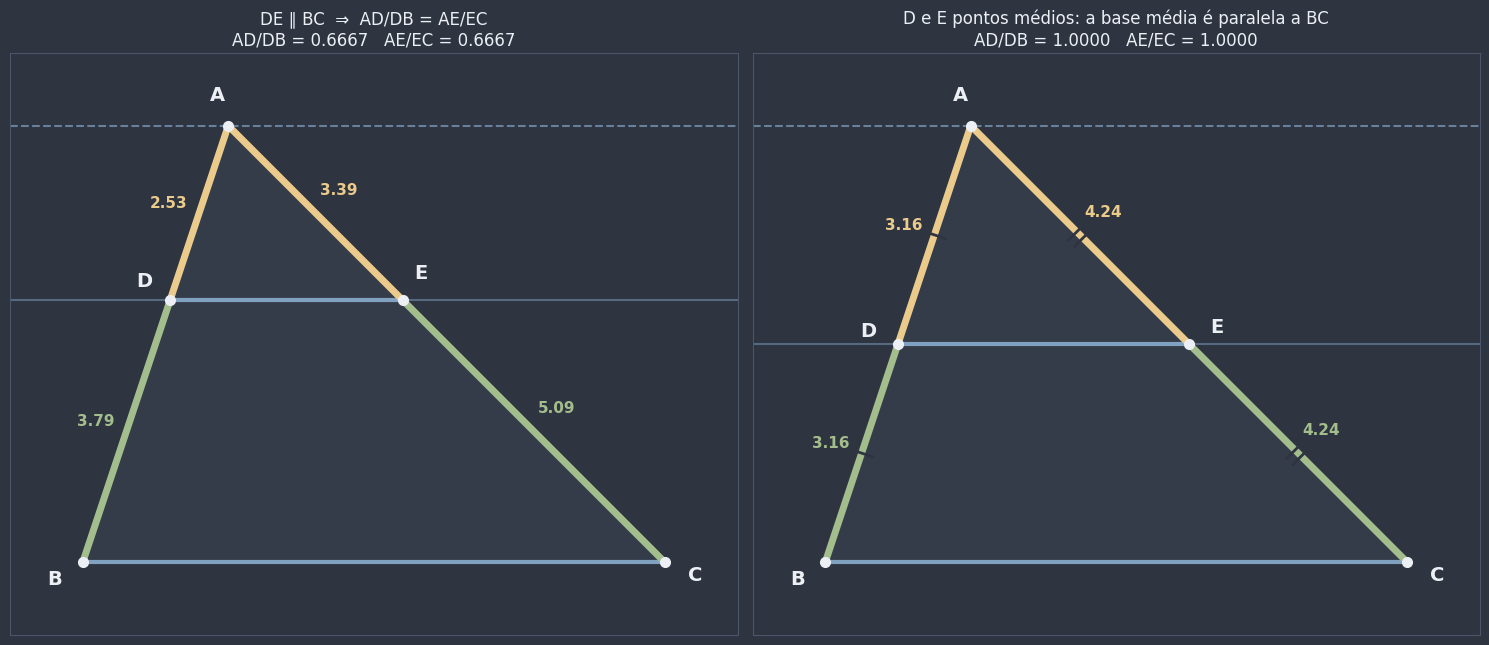

In [20]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 6.6))
fig.patch.set_facecolor(NORD_FUNDO)
for ax, fracao, titulo in ((eixos[0], 0.4, "DE ∥ BC  ⇒  AD/DB = AE/EC"),
                           (eixos[1], 0.5, "D e E pontos médios: a base média é paralela a BC")):
    D = A + fracao * (B - A)
    E = ponto_E_paralelo(A, B, C, D)
    preparar_eixo(ax, [A, B, C], margem=1.0)
    ax.add_patch(Polygon([A, B, C], closed=True, facecolor=COR_PARALELA, alpha=0.08, edgecolor="none"))
    desenhar_reta(ax, A, A + (C - B), cor=COR_PARALELA, estilo="--", largura=1.5, alpha=0.7)  # a paralela por A
    desenhar_segmento(ax, B, C, cor=COR_PARALELA, largura=3)
    desenhar_reta(ax, D, E, cor=COR_PARALELA, largura=1.5, alpha=0.5)
    desenhar_segmento(ax, D, E, cor=COR_PARALELA, largura=3)
    centro = (A + B + C) / 3
    for P, Q, cor in ((A, D, CORES_PARES[0]), (D, B, CORES_PARES[1]), (A, E, CORES_PARES[0]), (E, C, CORES_PARES[1])):
        desenhar_segmento(ax, P, Q, cor=cor, largura=5)
        rotular_segmento(ax, P, Q, f"{math.dist(P, Q):.2f}", cor=cor, distancia=0.45, longe_de=centro)
    if fracao == 0.5:
        for P, Q in ((A, D), (D, B)):
            marcar_congruentes(ax, P, Q, tracos=1, cor=NORD_FUNDO)
        for P, Q in ((A, E), (E, C)):
            marcar_congruentes(ax, P, Q, tracos=2, cor=NORD_FUNDO)
    for X, nome in ((A, "A"), (B, "B"), (C, "C"), (D, "D"), (E, "E")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, centro, distancia=0.45, tamanho=14)
    AD, DB, AE, EC = math.dist(A, D), math.dist(D, B), math.dist(A, E), math.dist(E, C)
    ax.set_title(f"{titulo}\nAD/DB = {AD / DB:.4f}   AE/EC = {AE / EC:.4f}", color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo:** no modo **"E calculado por Tales"**, o slider `D` move o ponto $D$ sobre $\overline{AB}$ e o ponto $E$ é recalculado para que $\overline{DE} \parallel \overline{BC}$; o painel mostra as duas razões, sempre iguais. No modo **"E livre"**, o slider `E` move o ponto $E$ sobre $\overline{AC}$ de forma independente, e o segmento $\overline{DE}$ só fica **verde** quando $AD/DB = AE/EC$: é o único momento em que ele é paralelo a $\overline{BC}$. Tente encontrar esse momento!

In [21]:
def explorar_triangulo(modo: str, posicao_D: float, posicao_E: float) -> None:
    A_w, B_w, C_w = np.array([2.0, 6.0]), np.array([0.0, 0.0]), np.array([8.0, 0.0])
    D_w = A_w + posicao_D * (B_w - A_w)
    E_w = ponto_E_paralelo(A_w, B_w, C_w, D_w) if modo == "tales" else A_w + posicao_E * (C_w - A_w)
    AD, DB, AE, EC = (math.dist(P, Q) for P, Q in ((A_w, D_w), (D_w, B_w), (A_w, E_w), (E_w, C_w)))
    paralelo = sao_paralelos(D_w, E_w, B_w, C_w)
    razoes_iguais = math.isclose(AD / DB, AE / EC, rel_tol=1e-6)

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(14, 6.4), gridspec_kw={"width_ratios": [1.2, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    preparar_eixo(ax, [A_w, B_w, C_w], margem=1.0)
    ax.add_patch(Polygon([A_w, B_w, C_w], closed=True, facecolor=COR_PARALELA, alpha=0.08, edgecolor="none"))
    desenhar_segmento(ax, B_w, C_w, cor=COR_PARALELA, largura=3)
    centro = (A_w + B_w + C_w) / 3
    for P, Q, cor in ((A_w, D_w, CORES_PARES[0]), (D_w, B_w, CORES_PARES[1]), (A_w, E_w, CORES_PARES[0]),
                      (E_w, C_w, CORES_PARES[1])):
        desenhar_segmento(ax, P, Q, cor=cor, largura=5)
        rotular_segmento(ax, P, Q, f"{math.dist(P, Q):.2f}", cor=cor, distancia=0.45, longe_de=centro)
    desenhar_segmento(ax, D_w, E_w, cor=COR_DESTAQUE if paralelo else COR_ALERTA, largura=3.5, zorder=6)
    for X, nome in ((A_w, "A"), (B_w, "B"), (C_w, "C"), (D_w, "D"), (E_w, "E")):
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, centro, distancia=0.45, tamanho=14)
    ax.set_title("DE ∥ BC" if paralelo else "DE não é paralelo a BC", color=COR_DESTAQUE if paralelo else COR_ALERTA,
                 fontsize=14)
    itens = [
        (f"AD/DB = {AD:.2f}/{DB:.2f} = {AD / DB:.4f}", True),
        (f"AE/EC = {AE:.2f}/{EC:.2f} = {AE / EC:.4f}", razoes_iguais),
        (f"AD/AB = {AD / (AD + DB):.4f}   e   AE/AC = {AE / (AE + EC):.4f}", razoes_iguais),
        (f"produto vetorial (DE, BC) = {produto_vetorial(E_w - D_w, C_w - B_w):+.4f}", paralelo),
        ("DE ∥ BC", paralelo),
    ]
    escrever_checklist(ax_lista, itens, "Tales no triângulo")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_triangulo,
    modo=widgets.Dropdown(options=[("E calculado por Tales", "tales"), ("E livre", "livre")], value="tales",
                          description="modo:"),
    posicao_D=widgets.FloatSlider(value=0.4, min=0.05, max=0.95, step=0.05, description="D:"),
    posicao_E=widgets.FloatSlider(value=0.6, min=0.05, max=0.95, step=0.05, description="E:"),
);

interactive(children=(Dropdown(description='modo:', options=(('E calculado por Tales', 'tales'), ('E livre', '…

⚠️ **Limite importante — o que Tales diz e o que ele não diz:** o teorema dá razões entre os segmentos **sobre os lados** $\overline{AB}$ e $\overline{AC}$ (as transversais): $\frac{AD}{DB}$, $\frac{AE}{EC}$, $\frac{AD}{AB}$, $\frac{AE}{AC}$. Ele **não** diz nada sobre o próprio segmento paralelo $\overline{DE}$. A afirmação

$$\frac{DE}{BC} = \frac{AD}{AB}$$

é **verdadeira**, mas **não decorre** do Teorema de Tales sozinho: $\overline{DE}$ e $\overline{BC}$ estão **sobre as paralelas**, não sobre as transversais (é o último ⚠️ da seção 3). Essa razão é consequência da **semelhança de triângulos**, tema de 📌 Semelhança de Triângulos e Potência de Ponto, cuja demonstração vai usar justamente o Teorema de Tales. Até lá, não use $\frac{DE}{BC}$ como se fosse Tales.

📎 **Conexão:** a **base média do triângulo** é o caso $D$ e $E$ pontos médios ($\frac{AD}{DB} = \frac{AE}{EC} = 1$). A **recíproca** de Tales prova de um jeito novo que ela é paralela a $\overline{BC}$. A medida $DE = \frac{BC}{2}$ é um caso especial da razão acima, que em [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb) foi demonstrado com congruência de triângulos; o caso geral, $\frac{DE}{BC} = \frac{AD}{AB}$, fica para a semelhança.

🎯 **Aplicação prática — telhados e estruturas:** num telhado de duas águas visto de frente (um triângulo), as **ripas** horizontais são paralelas à base. Se uma ripa está a $\frac{1}{3}$ do caminho do topo até a base numa das águas, ela também está a $\frac{1}{3}$ do caminho na outra água, e o carpinteiro marca as duas pontas pela mesma razão, sem medir ângulos.

**Pergunta de checagem:** num triângulo $ABC$, $\overline{DE} \parallel \overline{BC}$, com $D$ em $\overline{AB}$ e $E$ em $\overline{AC}$. Se $AD = 4$, $DB = 6$ e $AE = 5$, quanto vale $EC$?

**Pergunta de checagem:** no mesmo triângulo, um colega diz: "como $AD/AB = 4/10$, então $DE = 0{,}4 \cdot BC$, pelo Teorema de Tales". O resultado está certo? E a justificativa?

## 5. Teorema da bissetriz interna (e externa)

Em [`0403a_angulos.ipynb`](0403a_angulos.ipynb), a **bissetriz** de um ângulo era a semirreta que o divide em dois ângulos congruentes. Num triângulo, a bissetriz interna do ângulo $\hat{A}$ atravessa o triângulo e corta o lado oposto, $\overline{BC}$, num ponto $D$. Onde exatamente?

📌 **Teorema da bissetriz interna:** num triângulo $ABC$, a bissetriz interna do ângulo $\hat{A}$ corta o lado $\overline{BC}$ no ponto $D$ que o divide em segmentos **proporcionais aos lados adjacentes**:

$$\frac{BD}{DC} = \frac{AB}{AC}.$$

### Demonstração via Tales (a joia deste notebook)

Chame de $\alpha$ cada metade do ângulo $\hat{A}$: $B\hat{A}D = D\hat{A}C = \alpha$. Por $C$, trace a reta **paralela à bissetriz** $\overline{AD}$; ela corta o **prolongamento** do lado $\overline{BA}$ (além de $A$) num ponto $E$.

| Passo | Afirmação | Justificativa |
|---|---|---|
| 1 | $A\hat{C}E = D\hat{A}C = \alpha$ | ângulos **alternos internos**: $\overleftrightarrow{AD} \parallel \overleftrightarrow{CE}$, com a transversal $\overleftrightarrow{AC}$ ([`0406a_paralelismo.ipynb`](0406a_paralelismo.ipynb)) |
| 2 | $A\hat{E}C = B\hat{A}D = \alpha$ | ângulos **correspondentes**: $\overleftrightarrow{AD} \parallel \overleftrightarrow{CE}$, com a transversal $\overleftrightarrow{BE}$ |
| 3 | $A\hat{C}E = A\hat{E}C$ | passos 1 e 2 (e $B\hat{A}D = D\hat{A}C$, porque $\overline{AD}$ é bissetriz) |
| 4 | o triângulo $ACE$ é **isósceles**, com $AE = AC$ | ângulos da base congruentes ⇒ lados opostos congruentes ([`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb)) |
| 5 | $\dfrac{BD}{DC} = \dfrac{BA}{AE}$ | **Tales no triângulo** $BCE$ (seção 4): $\overline{AD}$ é paralelo ao lado $\overline{EC}$ e corta os lados $\overline{BE}$ e $\overline{BC}$ em $A$ e $D$ |
| 6 | $\dfrac{BD}{DC} = \dfrac{AB}{AC}$ | passos 4 e 5: troca-se $AE$ por $AC$ ∎ |

Repare quanta coisa se juntou nessa demonstração curta: ângulos alternos e correspondentes (0406a), triângulo isósceles (0405a), bissetriz (0403a) e Tales no triângulo (seção 4). É um momento em que o curso **se fecha em um ciclo**: ferramentas construídas em notebooks diferentes se encaixam para provar algo novo.

In [22]:
def pe_da_bissetriz(A, B, C) -> np.ndarray:
    """Pé D da bissetriz interna do ângulo A, no lado BC, pelo teorema da bissetriz: BD / DC = AB / AC.
    Ou seja, D divide BC na razão AB : AC (seção 1)."""
    return divide_segmento(B, C, math.dist(A, B), math.dist(A, C))


def pe_da_bissetriz_externa(A, B, C):
    """Ponto E da reta BC atingido pela bissetriz externa do ângulo A, com EB / EC = AB / AC e E FORA do
    segmento BC. Se AB = AC, a bissetriz externa é paralela a BC e não existe esse ponto: devolve None.

    Escrevendo E = B + λ·(C − B), a condição EB / EC = c / b (c = AB, b = AC) com E fora de BC dá λ = c / (c − b).
    """
    c, b = math.dist(A, B), math.dist(A, C)
    if iguais(b, c):
        return None
    B, C = np.asarray(B, dtype=float), np.asarray(C, dtype=float)
    return B + c / (c - b) * (C - B)


triangulos = {"A(2, 4), B(0, 0), C(7, 0)": ((2, 4), (0, 0), (7, 0)),
              "A(1, 5), B(0, 0), C(9, 0)": ((1, 5), (0, 0), (9, 0)),
              "A(5, 3), B(0, 0), C(6, 0)": ((5, 3), (0, 0), (6, 0)),
              "isósceles: A(3, 4), B(0, 0), C(6, 0)": ((3, 4), (0, 0), (6, 0))}
linhas = []
for nome, vertices in triangulos.items():
    A, B, C = (np.array(v, dtype=float) for v in vertices)
    D = pe_da_bissetriz(A, B, C)
    linhas.append({"triângulo": nome, "AB": f"{math.dist(A, B):.4f}", "AC": f"{math.dist(A, C):.4f}",
                   "BD": f"{math.dist(B, D):.4f}", "DC": f"{math.dist(D, C):.4f}",
                   "BD/DC": f"{math.dist(B, D) / math.dist(D, C):.6f}", "AB/AC": f"{math.dist(A, B) / math.dist(A, C):.6f}",
                   "ângulo BAD": f"{medir_angulo(A, B, D):.6f}°", "ângulo DAC": f"{medir_angulo(A, D, C):.6f}°"})
display(pd.DataFrame(linhas).style.hide(axis="index"))

triângulo,AB,AC,BD,DC,BD/DC,AB/AC,ângulo BAD,ângulo DAC
"A(2, 4), B(0, 0), C(7, 0)",4.4721,6.4031,2.8785,4.1215,0.698430,0.698430,38.952621°,38.952621°
"A(1, 5), B(0, 0), C(9, 0)",5.0990,9.4340,3.1577,5.8423,0.540495,0.540495,34.652275°,34.652275°
"A(5, 3), B(0, 0), C(6, 0)",5.8310,3.1623,3.8902,2.1098,1.843909,1.843909,38.735596°,38.735596°
"isósceles: A(3, 4), B(0, 0), C(6, 0)",5.0000,5.0000,3.0000,3.0000,1.000000,1.000000,36.869898°,36.869898°


A função `pe_da_bissetriz` encontra $D$ **só pela razão** $AB : AC$ (com `divide_segmento`), sem medir ângulo nenhum. Mesmo assim, o transferidor digital confirma: os ângulos $B\hat{A}D$ e $D\hat{A}C$ são iguais até a 6ª casa decimal, ou seja, $\overline{AD}$ é mesmo a bissetriz. Na última linha, o triângulo é isósceles ($AB = AC$) e $D$ cai no **ponto médio** de $\overline{BC}$.

A figura reconstrói a demonstração: o triângulo $ACE$ (laranja, isósceles) e os quatro ângulos $\alpha$.

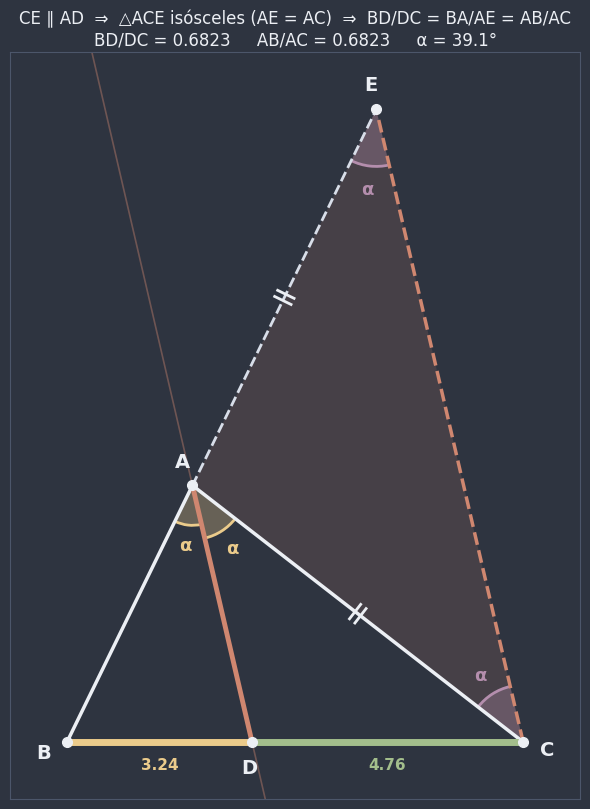

AE = 7.3410   AC = 7.3410
ACE = 39.1235°   AEC = 39.1235°   BAD = DAC = 39.1235°


In [23]:
A, B, C = np.array([2.2, 4.5]), np.array([0.0, 0.0]), np.array([8.0, 0.0])
D = pe_da_bissetriz(A, B, C)
E = cruzamento(C, direcao_de(A, D), B, direcao_de(B, A))  # a paralela a AD por C, no prolongamento de BA

fig, ax = plt.subplots(figsize=(10, 8.2))
fig.patch.set_facecolor(NORD_FUNDO)
preparar_eixo(ax, [A, B, C, E], margem=1.0)
ax.add_patch(Polygon([A, C, E], closed=True, facecolor=COR_BISSETRIZ, alpha=0.15, edgecolor="none"))
ax.add_patch(Polygon([A, B, C], closed=True, fill=False, edgecolor=NORD_TEXTO, lw=2.5, zorder=4))
desenhar_segmento(ax, A, E, cor=NORD_TEXTO_SEC, largura=2, estilo="--")  # prolongamento de BA
desenhar_reta(ax, A, D, cor=COR_BISSETRIZ, largura=1.2, alpha=0.4)
desenhar_segmento(ax, A, D, cor=COR_BISSETRIZ, largura=3.5)
desenhar_segmento(ax, C, E, cor=COR_BISSETRIZ, largura=2.5, estilo="--")
for P, Q in ((A, E), (A, C)):
    marcar_congruentes(ax, P, Q, tracos=2)
alfa = medir_angulo(A, B, D)
desenhar_arco(ax, A, B, D, raio=0.7, cor=COR_AVISO, rotulo="α", raio_rotulo=1.05, tamanho_fonte=13)
desenhar_arco(ax, A, D, C, raio=0.95, cor=COR_AVISO, rotulo="α", raio_rotulo=1.3, tamanho_fonte=13)
desenhar_arco(ax, C, A, E, raio=1.0, cor=COR_EXTRA, rotulo="α", raio_rotulo=1.4, tamanho_fonte=13)
desenhar_arco(ax, E, A, C, raio=1.0, cor=COR_EXTRA, rotulo="α", raio_rotulo=1.4, tamanho_fonte=13)
for P, Q, cor in ((B, D, CORES_PARES[0]), (D, C, CORES_PARES[1])):
    desenhar_segmento(ax, P, Q, cor=cor, largura=5)
    rotular_segmento(ax, P, Q, f"{math.dist(P, Q):.2f}", cor=cor, distancia=0.4, longe_de=A)
centro = (A + B + C) / 3
for X, nome in ((A, "A"), (B, "B"), (C, "C"), (D, "D"), (E, "E")):
    desenhar_ponto(ax, X, cor=NORD_TEXTO)
    rotular_fora(ax, X, nome, centro if nome != "E" else C, distancia=0.45, tamanho=14)
ax.set_title(f"CE ∥ AD  ⇒  △ACE isósceles (AE = AC)  ⇒  BD/DC = BA/AE = AB/AC\n"
             f"BD/DC = {math.dist(B, D) / math.dist(D, C):.4f}     AB/AC = {math.dist(A, B) / math.dist(A, C):.4f}     "
             f"α = {alfa:.1f}°", color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()
print(f"AE = {math.dist(A, E):.4f}   AC = {math.dist(A, C):.4f}")
print(f"ACE = {medir_angulo(C, A, E):.4f}°   AEC = {medir_angulo(E, A, C):.4f}°   BAD = DAC = {alfa:.4f}°")

### A bissetriz externa

O ângulo **externo** em $A$ (entre o lado $\overline{AC}$ e o prolongamento de $\overline{BA}$) também tem bissetriz, a **bissetriz externa**. Se $AB \neq AC$, ela corta a **reta** $BC$ num ponto $E$ **fora** do segmento $\overline{BC}$.

📌 **Teorema da bissetriz externa:** se $AB \neq AC$, a bissetriz externa do ângulo $\hat{A}$ corta a reta $BC$ num ponto $E$ tal que

$$\frac{EB}{EC} = \frac{AB}{AC}.$$

A demonstração é parecida com a da bissetriz interna (por $C$, uma paralela à bissetriz externa; aparece de novo um triângulo isósceles e Tales no triângulo): fica como exercício para quem quiser ir além. E se $AB = AC$? A bissetriz externa fica **paralela** a $\overline{BC}$ e não corta a reta $BC$.

Juntos, os dois teoremas dizem que a bissetriz interna e a externa de $\hat{A}$ dividem $\overline{BC}$ na **mesma razão** $AB : AC$, uma por dentro ($D$) e outra por fora ($E$). Os quatro pontos $B$, $C$, $D$ e $E$ formam o que se chama uma **divisão harmônica** (o nome é opcional). E há um bônus: as duas bissetrizes são **perpendiculares**, porque dividem ao meio dois ângulos suplementares (o interno e o externo): $\frac{\hat{A}}{2} + \frac{180° - \hat{A}}{2} = 90°$, como você viu com as bissetrizes de retas concorrentes em [`0403a_angulos.ipynb`](0403a_angulos.ipynb).

**No código:** a função `pe_da_bissetriz_externa` escreve $E = B + \lambda\,(C - B)$ e escolhe $\lambda$ para que $\frac{EB}{EC} = \frac{AB}{AC}$ com $E$ fora de $\overline{BC}$. A figura confere tudo: as duas razões e o ângulo reto entre as bissetrizes.

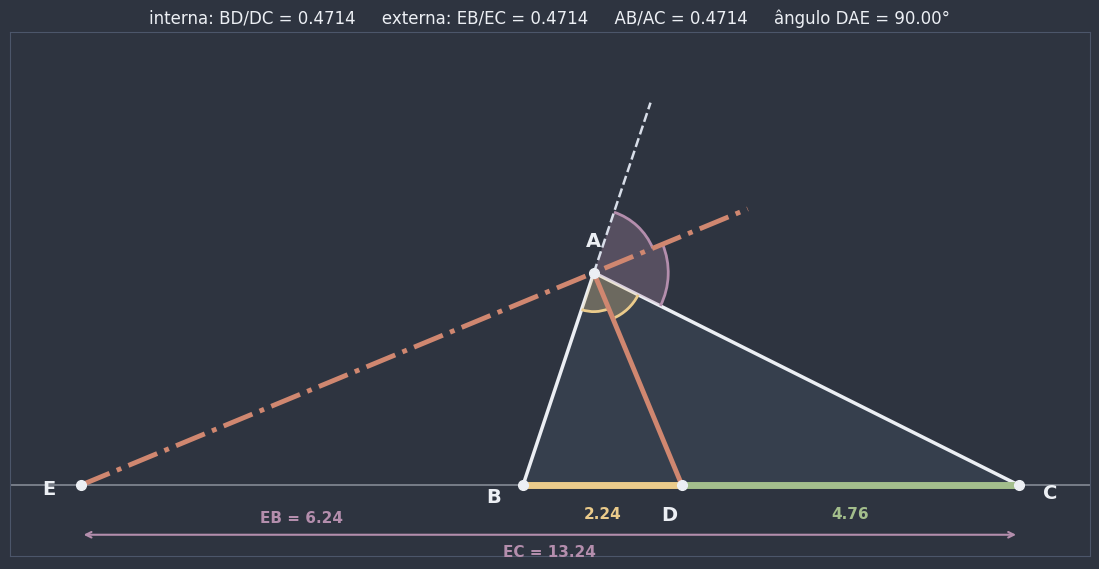

In [24]:
A, B, C = np.array([1.0, 3.0]), np.array([0.0, 0.0]), np.array([7.0, 0.0])
D = pe_da_bissetriz(A, B, C)
E = pe_da_bissetriz_externa(A, B, C)
B_prolongado = A + 0.8 * (A - B)  # um ponto do prolongamento de BA, além de A
F = A + 0.3 * (A - E)  # um ponto da bissetriz externa do outro lado de A (é ela que corta o ângulo externo)

fig, ax = plt.subplots(figsize=(15, 5.8))
fig.patch.set_facecolor(NORD_FUNDO)
preparar_eixo(ax, [A, B, C, E, B_prolongado, F], margem=1.0)
desenhar_reta(ax, B, C, cor=COR_TRANSVERSAL, largura=1.2, alpha=0.5)
ax.add_patch(Polygon([A, B, C], closed=True, facecolor=COR_PARALELA, alpha=0.1, edgecolor="none"))
ax.add_patch(Polygon([A, B, C], closed=True, fill=False, edgecolor=NORD_TEXTO, lw=2.5))
desenhar_segmento(ax, A, B_prolongado, cor=NORD_TEXTO_SEC, largura=1.8, estilo="--")
desenhar_segmento(ax, A, D, cor=COR_BISSETRIZ, largura=3.5)
desenhar_segmento(ax, E, F, cor=COR_BISSETRIZ, largura=3.5, estilo="-.")
desenhar_arco(ax, A, B, D, raio=0.55, cor=COR_AVISO)  # as duas metades do ângulo interno
desenhar_arco(ax, A, D, C, raio=0.7, cor=COR_AVISO)
desenhar_arco(ax, A, B_prolongado, F, raio=0.9, cor=COR_EXTRA)  # as duas metades do ângulo externo
desenhar_arco(ax, A, F, C, raio=1.05, cor=COR_EXTRA)
for P, Q, cor in ((B, D, CORES_PARES[0]), (D, C, CORES_PARES[1])):
    desenhar_segmento(ax, P, Q, cor=cor, largura=5)
    rotular_segmento(ax, P, Q, f"{math.dist(P, Q):.2f}", cor=cor, distancia=0.4, longe_de=A)
rotular_segmento(ax, E, B, f"EB = {math.dist(E, B):.2f}", cor=COR_EXTRA, distancia=0.45, longe_de=A)
ax.text(*((E + C) / 2 - np.array([0, 1.0])), f"EC = {math.dist(E, C):.2f}", color=COR_EXTRA, fontsize=11,
        fontweight="bold", ha="center")
ax.annotate("", xy=C - np.array([0, 0.7]), xytext=E - np.array([0, 0.7]),
            arrowprops={"arrowstyle": "<->", "color": COR_EXTRA, "lw": 1.5})
centro = (A + B + C) / 3
for X, nome in ((A, "A"), (B, "B"), (C, "C"), (D, "D"), (E, "E")):
    desenhar_ponto(ax, X, cor=NORD_TEXTO)
    rotular_fora(ax, X, nome, centro if nome != "A" else (A[0], 0), distancia=0.45, tamanho=14)
AB_, AC_ = math.dist(A, B), math.dist(A, C)
ax.set_title(f"interna: BD/DC = {math.dist(B, D) / math.dist(D, C):.4f}     externa: EB/EC = "
             f"{math.dist(E, B) / math.dist(E, C):.4f}     AB/AC = {AB_ / AC_:.4f}     "
             f"ângulo DAE = {medir_angulo(A, D, E):.2f}°", color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo:** os sliders `x de A` e `y de A` movem o vértice $A$ ($B$ e $C$ ficam fixos). O pé $D$ da bissetriz interna e as razões $BD/DC$ e $AB/AC$ são recalculados, junto com os ângulos $B\hat{A}D$ e $D\hat{A}C$. Ligue `bissetriz externa` para ver também o ponto $E$ (ele foge para longe quando $AB$ e $AC$ ficam quase iguais, e some quando são iguais). Tente: (1) deixar o triângulo isósceles ($x = 3{,}5$); (2) observar para que lado o ponto $D$ "se inclina" quando $AB$ é bem menor que $AC$.

In [ ]:
def explorar_bissetriz(x_A: float, y_A: float, externa: bool) -> None:
    A_w, B_w, C_w = np.array([x_A, y_A]), np.array([0.0, 0.0]), np.array([7.0, 0.0])
    D_w = pe_da_bissetriz(A_w, B_w, C_w)
    E_w = pe_da_bissetriz_externa(A_w, B_w, C_w) if externa else None
    AB_w, AC_w, BD, DC = math.dist(A_w, B_w), math.dist(A_w, C_w), math.dist(B_w, D_w), math.dist(D_w, C_w)
    BAD, DAC = medir_angulo(A_w, B_w, D_w), medir_angulo(A_w, D_w, C_w)

    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1.25, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    enquadrar = [A_w, B_w, C_w, (-1, -0.5), (8, 6.5)]
    if E_w is not None and abs(E_w[0]) < 30:
        enquadrar.append(E_w)
    preparar_eixo(ax, enquadrar, margem=0.8)
    ax.add_patch(Polygon([A_w, B_w, C_w], closed=True, facecolor=COR_PARALELA, alpha=0.1, edgecolor="none"))
    ax.add_patch(Polygon([A_w, B_w, C_w], closed=True, fill=False, edgecolor=NORD_TEXTO, lw=2.5))
    desenhar_segmento(ax, A_w, D_w, cor=COR_BISSETRIZ, largura=3.5)
    desenhar_arco(ax, A_w, B_w, D_w, raio=0.6, cor=COR_AVISO, rotulo=f"{BAD:.1f}°", raio_rotulo=1.15)
    desenhar_arco(ax, A_w, D_w, C_w, raio=0.8, cor=COR_AVISO, rotulo=f"{DAC:.1f}°", raio_rotulo=1.45)
    for P, Q, cor in ((B_w, D_w, CORES_PARES[0]), (D_w, C_w, CORES_PARES[1])):
        desenhar_segmento(ax, P, Q, cor=cor, largura=5)
        rotular_segmento(ax, P, Q, f"{math.dist(P, Q):.2f}", cor=cor, distancia=0.4, longe_de=A_w)
    pontos = [(A_w, "A"), (B_w, "B"), (C_w, "C"), (D_w, "D")]
    if externa and E_w is not None:
        desenhar_reta(ax, B_w, C_w, cor=COR_TRANSVERSAL, largura=1.2, alpha=0.5)
        desenhar_segmento(ax, A_w, E_w, cor=COR_BISSETRIZ, largura=3, estilo="-.")
        pontos.append((E_w, "E"))
    centro = (A_w + B_w + C_w) / 3
    for X, nome in pontos:
        desenhar_ponto(ax, X, cor=NORD_TEXTO)
        rotular_fora(ax, X, nome, centro if nome != "A" else (A_w[0], 0), distancia=0.45, tamanho=14)
    ax.set_title(f"BD/DC = {BD / DC:.4f}     AB/AC = {AB_w / AC_w:.4f}", color=NORD_TEXTO, fontsize=13)
    itens = [
        (f"AB = {AB_w:.3f},  AC = {AC_w:.3f}  →  AB/AC = {AB_w / AC_w:.4f}", True),
        (f"BD = {BD:.3f},  DC = {DC:.3f}  →  BD/DC = {BD / DC:.4f}", iguais(BD / DC, AB_w / AC_w)),
        (f"BAD = {BAD:.3f}°  e  DAC = {DAC:.3f}°", math.isclose(BAD, DAC, abs_tol=1e-6)),
        ("o segmento maior (BD ou DC) fica do lado do lado maior", (BD >= DC) == (AB_w >= AC_w)),
        ("triângulo isósceles (AB = AC): D é o ponto médio de BC", math.isclose(AB_w, AC_w, abs_tol=1e-9)),
    ]
    if externa:
        if E_w is None:
            itens.append(("AB = AC: a bissetriz externa é paralela a BC", False))
        else:
            itens.append((f"EB/EC = {math.dist(E_w, B_w) / math.dist(E_w, C_w):.4f};  ângulo DAE = "
                          f"{medir_angulo(A_w, D_w, E_w):.2f}°", iguais(math.dist(E_w, B_w) / math.dist(E_w, C_w),
                                                                       AB_w / AC_w)))
    escrever_checklist(ax_lista, itens, "Teorema da bissetriz")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_bissetriz,
    x_A=widgets.FloatSlider(value=2.0, min=-1.0, max=8.0, step=0.25, description="x de A:"),
    y_A=widgets.FloatSlider(value=4.0, min=1.0, max=6.0, step=0.25, description="y de A:"),
    externa=widgets.Checkbox(value=False, description="bissetriz externa"),
);

interactive(children=(FloatSlider(value=2.0, description='x de A:', max=8.0, min=-1.0, step=0.25), FloatSlider…

💡 **Dica:** se o triângulo é **isósceles** ($AB = AC$), a razão é $\frac{BD}{DC} = 1$ e a bissetriz cai no **ponto médio** de $\overline{BC}$. É o que você viu em [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) e em [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb): no triângulo isósceles, a bissetriz do ângulo do vértice, a mediana e a altura relativas à base **coincidem**.

⚠️ **Erro comum:** trocar os lados na proporção, escrevendo $\frac{BD}{DC} = \frac{AC}{AB}$. Regra para lembrar: o segmento **adjacente** ao lado maior é o **maior** ($\overline{BD}$ encosta em $B$, a ponta do lado $\overline{AB}$). Teste num caso concreto: com $AB = 9$ e $AC = 6$, o pedaço $\overline{BD}$ (do lado de $\overline{AB}$, que é maior) tem de ser o maior. Visualmente, a bissetriz "se inclina" para o lado do **menor** lado adjacente.

🕵️ **Curiosidade (leitura opcional) — a circunferência de Apolônio:** fixe dois pontos $A$ e $B$ e uma razão $k \neq 1$. Quais pontos $P$ do plano satisfazem $\frac{PA}{PB} = k$? A resposta, estudada por **Apolônio de Perga** (século III a.C.), é uma **circunferência**. A ideia da prova junta tudo: no triângulo $APB$, as bissetrizes interna e externa do ângulo $\hat{P}$ cortam a reta $AB$ em dois pontos $D$ e $E$, e, pelos dois teoremas desta seção, ambos dividem $\overline{AB}$ na razão $k$, por dentro e por fora. Então $D$ e $E$ são **sempre os mesmos dois pontos**, qualquer que seja $P$! Como as duas bissetrizes são perpendiculares, $P$ enxerga $\overline{DE}$ sob um ângulo de 90°, e por isso está na circunferência de diâmetro $\overline{DE}$ (o arco capaz de 90°, de [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb)). É mais um **lugar geométrico** para a coleção do curso, ao lado da mediatriz, da bissetriz e do arco capaz. Você vai caçar essa circunferência no Desafio 7.

🎯 **Aplicação prática — reflexão e equilíbrio de forças:** num espelho, o raio de luz que chega e o que sai fazem ângulos iguais com a reta perpendicular ao espelho: essa perpendicular é a **bissetriz** do ângulo entre os dois raios. Em física, quando duas forças de mesma intensidade puxam um objeto em direções diferentes, a força resultante aponta na direção da bissetriz do ângulo entre elas; com intensidades diferentes, ela "se inclina" para a força maior, numa proporção que lembra o teorema desta seção.

📖 **Leitura complementar:** [Bissetriz](https://pt.wikipedia.org/wiki/Bissetriz), [Angle bisector theorem](https://en.wikipedia.org/wiki/Angle_bisector_theorem) (em inglês) e [Circles of Apollonius](https://en.wikipedia.org/wiki/Circles_of_Apollonius) (em inglês)

📎 **Conexão:** este notebook diz **onde** a bissetriz corta o lado oposto. O **comprimento** da bissetriz (a medida de $\overline{AD}$) será calculado em 📌 Triângulos Quaisquer. E, combinando a bissetriz de dois ângulos, dá para descobrir em que razão o **incentro** de [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) divide cada bissetriz: $\frac{AI}{ID} = \frac{AB + AC}{BC}$ (tente provar aplicando o teorema da bissetriz no triângulo $ABD$!).

**Pergunta de checagem:** num triângulo $ABC$, $AB = 9$, $AC = 6$ e $BC = 10$. A bissetriz interna de $\hat{A}$ divide $\overline{BC}$ em dois segmentos. Quanto medem?

**Pergunta de checagem:** na demonstração do teorema da bissetriz, por que foi importante traçar a paralela à bissetriz **por $C$**, e não por um ponto qualquer?

## Resumo — cheat sheet

| Conceito | Ideia-chave |
|---|---|
| **Razão entre segmentos** | $\dfrac{AB}{CD}$, com as medidas na **mesma unidade**; é um número sem unidade |
| **Proporção** | $\dfrac{a}{b} = \dfrac{c}{d} \iff a \cdot d = b \cdot c$ (produto dos meios = produto dos extremos) |
| **Propriedades** | soma: $\dfrac{a + b}{b} = \dfrac{c + d}{d}$; troca dos meios: $\dfrac{a}{c} = \dfrac{b}{d}$ |
| **Dividir $\overline{AB}$ na razão $m : n$** | $P = A + \dfrac{m}{m + n}(B - A)$; $1 : 1$ é o ponto médio, $2 : 1$ é a posição do baricentro na mediana |
| **Lema** | paralelas que cortam segmentos **congruentes** numa transversal cortam segmentos congruentes em **qualquer** outra (prova: paralelogramos + ALA) |
| **Dividir em $n$ partes iguais** | semirreta auxiliar, $n$ marcas com o compasso, ligar a última a $B$ e traçar paralelas |
| **Teorema de Tales** | feixe de paralelas cortado por duas transversais ⇒ segmentos proporcionais: $\dfrac{AB}{BC} = \dfrac{A'B'}{B'C'}$ e $\dfrac{AB}{A'B'} = \dfrac{BC}{B'C'}$ |
| **Comensurável × incomensurável** | demonstrado com uma medida comum $u$; vale também para razões irracionais (ideia de limite) |
| **Tales no triângulo** | $\overline{DE} \parallel \overline{BC}$ ⇒ $\dfrac{AD}{DB} = \dfrac{AE}{EC}$ e $\dfrac{AD}{AB} = \dfrac{AE}{AC}$ |
| **Recíproca** | $\dfrac{AD}{DB} = \dfrac{AE}{EC}$ ⇒ $\overline{DE} \parallel \overline{BC}$ (serve para **provar** paralelismo) |
| ⚠️ **Cuidado** | $\dfrac{DE}{BC} = \dfrac{AD}{AB}$ é verdade, mas **não** vem de Tales: vem da semelhança (📌 Semelhança de Triângulos e Potência de Ponto) |
| **Bissetriz interna** | $\dfrac{BD}{DC} = \dfrac{AB}{AC}$ (prova: paralela à bissetriz por $C$, triângulo isósceles e Tales) |
| **Bissetriz externa** | $\dfrac{EB}{EC} = \dfrac{AB}{AC}$, com $E$ fora de $\overline{BC}$ (só se $AB \neq AC$); as duas bissetrizes são perpendiculares |

**Dica de memória:** a bissetriz divide o lado oposto **na mesma razão dos lados adjacentes**.

**O que é Tales e o que não é:** razões entre segmentos **sobre as transversais** → Tales. Razões que envolvem os segmentos **sobre as paralelas** ($\overline{DE}$, $\overline{BC}$, $\overline{AA'}$...) → não é Tales.

As figuras abaixo repetem as cores do notebook: paralelas em azul, segmentos correspondentes com a mesma cor (amarelo com amarelo, verde com verde) e bissetriz em laranja.

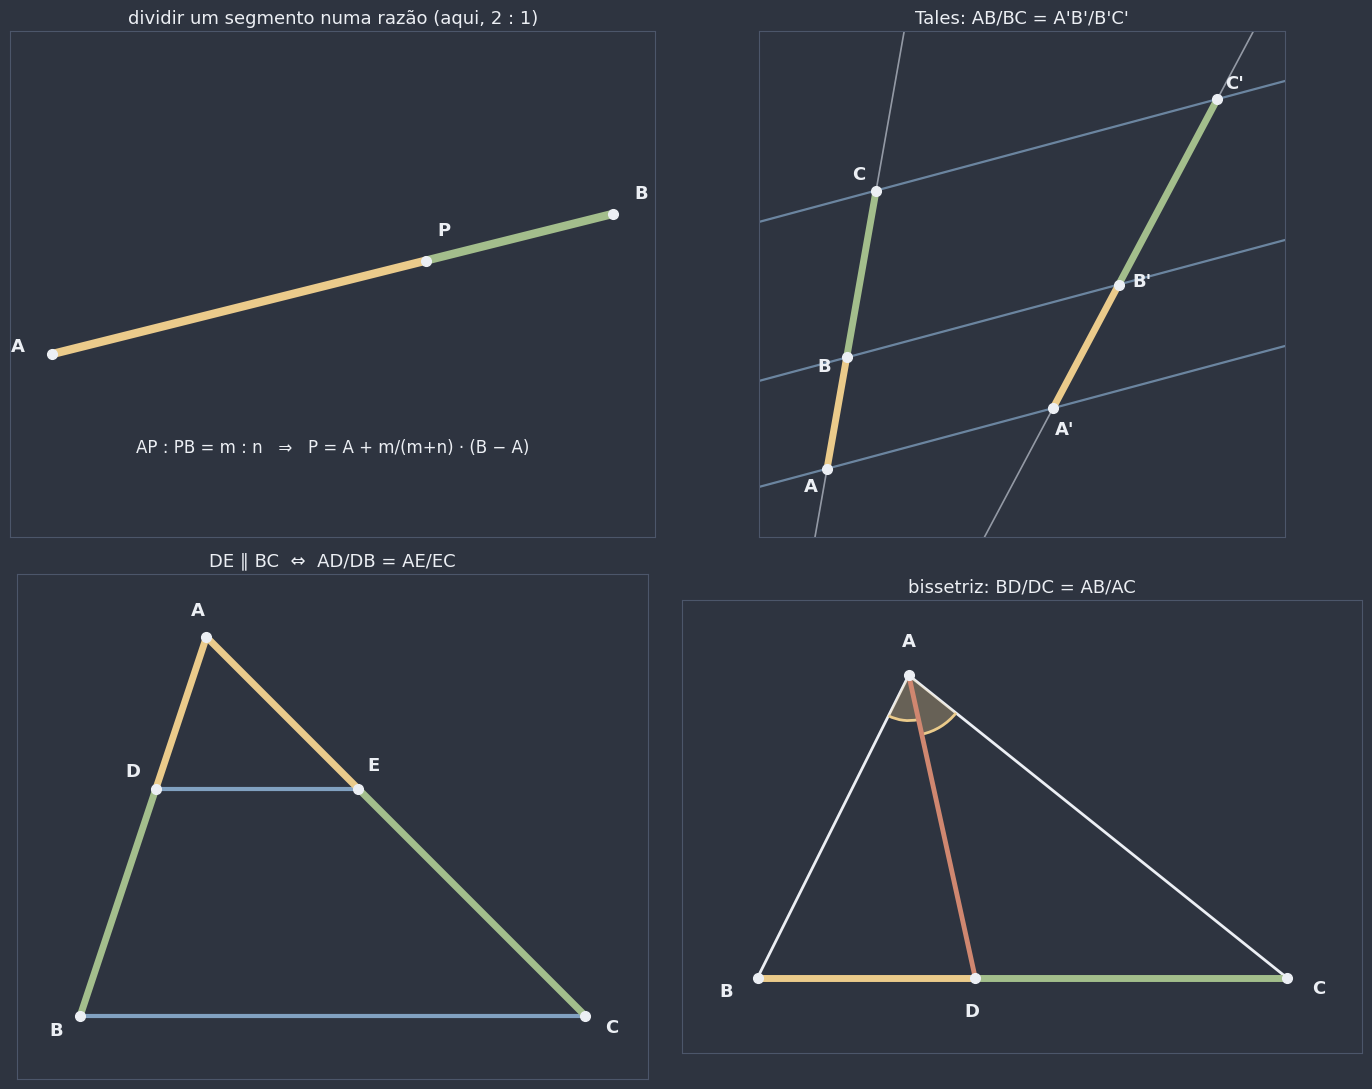

In [26]:
fig, eixos = plt.subplots(2, 2, figsize=(14, 11))
fig.patch.set_facecolor(NORD_FUNDO)

# Dividir na razão m : n
ax = eixos[0, 0]
A_c, B_c = np.array([0.0, 0.0]), np.array([8.0, 2.0])
P_c = divide_segmento(A_c, B_c, 2, 1)
preparar_eixo(ax, [A_c, B_c, (0, 4), (8, -2)], margem=0.6)
desenhar_segmento(ax, A_c, P_c, cor=CORES_PARES[0], largura=6)
desenhar_segmento(ax, P_c, B_c, cor=CORES_PARES[1], largura=6)
for X, nome in ((A_c, "A"), (P_c, "P"), (B_c, "B")):
    desenhar_ponto(ax, X, cor=NORD_TEXTO)
    rotular_fora(ax, X, nome, (4, -1), distancia=0.5, tamanho=13)
ax.text(4, -1.4, "AP : PB = m : n   ⇒   P = A + m/(m+n) · (B − A)", color=NORD_TEXTO, fontsize=12, ha="center")
ax.set_title("dividir um segmento numa razão (aqui, 2 : 1)", color=NORD_TEXTO, fontsize=13)

# Teorema de Tales
ax = eixos[0, 1]
pontos_c = pontos_na_transversal((0, 0), 80, [2, 3])
pontos_c2 = cortes_na_transversal(pontos_c, 15, np.array([4.0, 4.0 * math.tan(math.radians(15))]), 62)
preparar_eixo(ax, pontos_c + pontos_c2, margem=1.2)
desenhar_feixe(ax, pontos_c, pontos_c2, nomes="ABC", rotular_medidas=False)
ax.set_title("Tales: AB/BC = A'B'/B'C'", color=NORD_TEXTO, fontsize=13)

# Tales no triângulo
ax = eixos[1, 0]
A_c, B_c, C_c = np.array([2.0, 6.0]), np.array([0.0, 0.0]), np.array([8.0, 0.0])
D_c = A_c + 0.4 * (B_c - A_c)
E_c = ponto_E_paralelo(A_c, B_c, C_c, D_c)
preparar_eixo(ax, [A_c, B_c, C_c], margem=1.0)
desenhar_segmento(ax, B_c, C_c, cor=COR_PARALELA, largura=3)
desenhar_segmento(ax, D_c, E_c, cor=COR_PARALELA, largura=3)
for P, Q, cor in ((A_c, D_c, CORES_PARES[0]), (D_c, B_c, CORES_PARES[1]), (A_c, E_c, CORES_PARES[0]),
                  (E_c, C_c, CORES_PARES[1])):
    desenhar_segmento(ax, P, Q, cor=cor, largura=5)
for X, nome in ((A_c, "A"), (B_c, "B"), (C_c, "C"), (D_c, "D"), (E_c, "E")):
    desenhar_ponto(ax, X, cor=NORD_TEXTO)
    rotular_fora(ax, X, nome, (A_c + B_c + C_c) / 3, distancia=0.45, tamanho=13)
ax.set_title("DE ∥ BC  ⇔  AD/DB = AE/EC", color=NORD_TEXTO, fontsize=13)

# Bissetriz interna
ax = eixos[1, 1]
A_c, B_c, C_c = np.array([2.0, 4.0]), np.array([0.0, 0.0]), np.array([7.0, 0.0])
D_c = pe_da_bissetriz(A_c, B_c, C_c)
preparar_eixo(ax, [A_c, B_c, C_c], margem=1.0)
ax.add_patch(Polygon([A_c, B_c, C_c], closed=True, fill=False, edgecolor=NORD_TEXTO, lw=2))
desenhar_segmento(ax, A_c, D_c, cor=COR_BISSETRIZ, largura=3.5)
desenhar_arco(ax, A_c, B_c, D_c, raio=0.6, cor=COR_AVISO)
desenhar_arco(ax, A_c, D_c, C_c, raio=0.8, cor=COR_AVISO)
for P, Q, cor in ((B_c, D_c, CORES_PARES[0]), (D_c, C_c, CORES_PARES[1])):
    desenhar_segmento(ax, P, Q, cor=cor, largura=5)
for X, nome in ((A_c, "A"), (B_c, "B"), (C_c, "C"), (D_c, "D")):
    desenhar_ponto(ax, X, cor=NORD_TEXTO)
    rotular_fora(ax, X, nome, (A_c + B_c + C_c) / 3 if nome != "A" else (2, 0), distancia=0.45, tamanho=13)
ax.set_title("bissetriz: BD/DC = AB/AC", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

## Exercícios

**Básico**
1. Tales no feixe de paralelas: calcule o segmento que falta (com e sem a propriedade da soma).
2. Tales no triângulo: segmento desconhecido, a segunda forma e a recíproca.

**Intermediário**

3. Duas maneiras de dividir um segmento: a fórmula e a construção da folha pautada.
4. O pé das bissetrizes interna e externa, conferido com o transferidor.
5. Problemas de vários passos: Tales + bissetriz.

**Desafio**

6. A demonstração do 2 : 1 do baricentro.
7. Caçando a circunferência de Apolônio.

Gabarito completo com resolução comentada em [`0414b_teorema_de_tales_gabarito.ipynb`](0414b_teorema_de_tales_gabarito.ipynb) — tente resolver sozinho antes de olhar.

### Básico

In [ ]:
# Exercício Básico 1: Tales no feixe de paralelas. Em todos os itens, três (ou mais) retas paralelas cortam a
# transversal t em A, B, C e a transversal t' em A', B', C', nessa ordem.
# (a) AB = 4, BC = 6 e A'B' = 6. Guarde B'C' em `B2C2_ex1a`.
# (b) AC = 15 (o segmento inteiro), AB = 6 e A'B' = 8. Guarde A'C' em `A2C2_ex1b` e B'C' em `B2C2_ex1b`.
#     (Dica: propriedade da soma.)
# (c) AB = x + 1, BC = 6, A'B' = 4 e B'C' = 8. Guarde o valor de x em `x_ex1c`.
# (d) Os lotes do gancho com outros números: na avenida da esquerda, os trechos medem 25 m e 35 m; na da
#     direita, o primeiro trecho mede 20 m. Guarde o segundo trecho da direita em `trecho_ex1d`.
B2C2_ex1a = ...
A2C2_ex1b = ...
B2C2_ex1b = ...
x_ex1c = ...
trecho_ex1d = ...

print(B2C2_ex1a, A2C2_ex1b, B2C2_ex1b, x_ex1c, trecho_ex1d)

In [ ]:
# Verificação
assert B2C2_ex1a is not ... and math.isclose(B2C2_ex1a, 9), (
    "Tente de novo, revise: AB/BC = A'B'/B'C', e o produto dos meios é igual ao produto dos extremos "
    "(seção 3 - O Teorema de Tales)."
)
assert A2C2_ex1b is not ... and math.isclose(A2C2_ex1b, 20), (
    "Tente de novo, revise: pela troca dos meios, AB/A'B' = AC/A'C' (o fator de t para t' é o mesmo para todos "
    "os segmentos) (seção 3 - O Teorema de Tales)."
)
assert B2C2_ex1b is not ... and math.isclose(B2C2_ex1b, 12), (
    "Tente de novo, revise: B'C' = A'C' − A'B' (seção 1 - Razão e proporção entre segmentos)."
)
assert x_ex1c is not ... and math.isclose(x_ex1c, 2), (
    "Tente de novo, revise: monte (x + 1)/6 = 4/8 e resolva a equação (seção 3 - O Teorema de Tales)."
)
assert trecho_ex1d is not ... and math.isclose(trecho_ex1d, 28), (
    "Tente de novo, revise: 25/35 = 20/x, com os trechos correspondentes entre as mesmas duas ruas "
    "(seção 3 - O Teorema de Tales)."
)
print("Certo!")

In [ ]:
# Exercício Básico 2: Tales no triângulo. No triângulo ABC, D está no lado AB e E está no lado AC.
# (a) DE ∥ BC, AD = 3, DB = 5 e AE = 4,5. Guarde EC em `EC_ex2a`.
# (b) DE ∥ BC, AB = 12, AD = 8 e AC = 15. Guarde AE em `AE_ex2b`.
# (c) DE ∥ BC, AD = x, DB = x + 3, AE = 4 e EC = 7. Guarde o valor de x em `x_ex2c`.
# (d) A recíproca: decida, pelas razões, se DE é paralelo a BC. Guarde True ou False:
#     - em `paralelo_ex2d1`, para AD = 2, DB = 3, AE = 2,4 e EC = 3,6;
#     - em `paralelo_ex2d2`, para AD = 3, DB = 4, AE = 4 e EC = 5.
#     (Use iguais para comparar as razões, em vez de ==.)
EC_ex2a = ...
AE_ex2b = ...
x_ex2c = ...
paralelo_ex2d1 = ...
paralelo_ex2d2 = ...

print(EC_ex2a, AE_ex2b, x_ex2c, paralelo_ex2d1, paralelo_ex2d2)

In [ ]:
# Verificação
assert EC_ex2a is not ... and math.isclose(EC_ex2a, 7.5), (
    "Tente de novo, revise: AD/DB = AE/EC (seção 4 - Tales no triângulo)."
)
assert AE_ex2b is not ... and math.isclose(AE_ex2b, 10), (
    "Tente de novo, revise: a segunda forma, AD/AB = AE/AC (seção 4 - Tales no triângulo)."
)
assert x_ex2c is not ... and math.isclose(x_ex2c, 4), (
    "Tente de novo, revise: monte x/(x + 3) = 4/7 e use o produto dos meios e dos extremos (seção 4 - Tales no "
    "triângulo)."
)
assert paralelo_ex2d1 is not ... and bool(paralelo_ex2d1), (
    "Tente de novo, revise: 2/3 e 2,4/3,6 são a mesma razão, então DE ∥ BC pela recíproca (seção 4 - Tales no "
    "triângulo)."
)
assert paralelo_ex2d2 is not ... and not bool(paralelo_ex2d2), (
    "Tente de novo, revise: 3/4 e 4/5 são razões diferentes, então DE não é paralelo a BC (seção 4 - Tales no "
    "triângulo)."
)
print("Certo!")

### Intermediário

In [ ]:
# Exercício Intermediário 3: duas maneiras de dividir um segmento.
# (a) Complete divide_segmento_ex3(A, B, m, n), que devolve o ponto P de AB com AP/PB = m/n, pela fórmula
#     P = A + m/(m + n)·(B − A). Converta A e B com np.asarray(..., dtype=float). (Não use divide_segmento.)
# (b) Complete divide_por_paralelas_ex3(A, B, n, angulo_auxiliar), que devolve a LISTA dos n − 1 pontos que
#     dividem AB em n partes iguais, pela construção da seção 2 (não use dividir_por_paralelas):
#       - Q_k = A + k·direcao(direcao_de(A, B) + angulo_auxiliar), para k = 1, ..., n (compasso de abertura 1);
#       - por cada Q_k, com k = 1, ..., n − 1, a paralela a Q_nB cruza a reta AB no ponto
#         cruzamento(Q_k, direcao_de(Q_n, B), A, direcao_de(A, B)).
# (c) Para A = (1, 2), B = (11, 6), n = 7 e ângulo auxiliar de 40°, guarde em `maior_diferenca_ex3` a maior
#     distância entre o k-ésimo ponto da construção e divide_segmento_ex3(A, B, k, n − k), para k = 1, ..., 6.


def divide_segmento_ex3(A, B, m: float, n: float) -> np.ndarray:
    ...


def divide_por_paralelas_ex3(A, B, n: int, angulo_auxiliar: float) -> list:
    ...


maior_diferenca_ex3 = ...

print(divide_segmento_ex3((0, 0), (10, 5), 3, 2), maior_diferenca_ex3)

In [ ]:
# Verificação
for (A_t, B_t, m_t, n_t, P_certo) in [((0, 0), (10, 5), 3, 2, (6, 3)), ((1, 1), (9, 5), 1, 1, (5, 3)),
                                      ((-2, 4), (4, -2), 2, 1, (2, 0))]:
    P_t = divide_segmento_ex3(A_t, B_t, m_t, n_t)
    assert P_t is not None and np.allclose(P_t, P_certo), (
        f"Tente de novo, revise: com A = {A_t}, B = {B_t} e razão {m_t} : {n_t}, P = {P_certo}; P anda m/(m + n) "
        "do caminho de A até B (seção 1 - Razão e proporção entre segmentos)."
    )
gerador_ex3 = np.random.default_rng(3)
for _ in range(30):
    A_t, B_t = gerador_ex3.uniform(-5, 5, 2), gerador_ex3.uniform(-5, 5, 2)
    if math.dist(A_t, B_t) < 1:
        continue
    n_t = int(gerador_ex3.integers(2, 10))
    angulo_t = gerador_ex3.uniform(15, 165)
    pontos_t = divide_por_paralelas_ex3(A_t, B_t, n_t, angulo_t)
    assert pontos_t is not None and len(pontos_t) == n_t - 1, (
        "Tente de novo, revise: a construção devolve n − 1 pontos de divisão (seção 2 - Feixe de paralelas e o lema "
        "dos segmentos congruentes)."
    )
    for k, X in enumerate(pontos_t, start=1):
        assert np.allclose(X, divide_segmento(A_t, B_t, k, n_t - k)), (
            "Tente de novo, revise: cada paralela a Q_nB passa por Q_k e corta a reta AB (seção 2 - Feixe de "
            "paralelas e o lema dos segmentos congruentes)."
        )
assert maior_diferenca_ex3 is not ... and maior_diferenca_ex3 < 1e-9, (
    "Tente de novo, revise: compare cada ponto da construção com divide_segmento_ex3(A, B, k, n − k) e guarde a "
    "maior distância (seção 2 - Feixe de paralelas e o lema dos segmentos congruentes)."
)
print("Certo!")

In [ ]:
# Exercício Intermediário 4: o pé das bissetrizes.
# (a) Complete pe_bissetriz_interna_ex4(A, B, C), que devolve o ponto D do lado BC atingido pela bissetriz interna
#     do ângulo A, usando o teorema da bissetriz: D divide BC na razão AB : AC (use divide_segmento).
# (b) Complete pe_bissetriz_externa_ex4(A, B, C), que devolve o ponto E da reta BC atingido pela bissetriz externa
#     (suponha AB ≠ AC). Use E = B + λ·(C − B), com λ = c/(c − b), em que c = AB e b = AC.
#     (Não use pe_da_bissetriz nem pe_da_bissetriz_externa do notebook.)
# (c) Para o triângulo A = (2, 5), B = (0, 0), C = (9, 0), guarde D em `D_ex4`, E em `E_ex4` e, na tupla
#     `angulos_ex4`, os ângulos (BAD, DAC) medidos com medir_angulo. Guarde também em `DAE_ex4` o ângulo entre as
#     duas bissetrizes (com vértice em A, entre D e E).


def pe_bissetriz_interna_ex4(A, B, C) -> np.ndarray:
    ...


def pe_bissetriz_externa_ex4(A, B, C) -> np.ndarray:
    ...


D_ex4 = ...
E_ex4 = ...
angulos_ex4 = ...
DAE_ex4 = ...

print(D_ex4, E_ex4, angulos_ex4, DAE_ex4)

In [ ]:
# Verificação
gerador_ex4 = np.random.default_rng(4)
testados = 0
while testados < 40:
    A_t, B_t, C_t = gerador_ex4.uniform(-5, 5, (3, 2))
    if abs(produto_vetorial(B_t - A_t, C_t - A_t)) < 2 or abs(math.dist(A_t, B_t) - math.dist(A_t, C_t)) < 0.5:
        continue  # descarta triângulos quase "achatados" e quase isósceles
    testados += 1
    D_t = pe_bissetriz_interna_ex4(A_t, B_t, C_t)
    assert D_t is not None and math.isclose(medir_angulo(A_t, B_t, D_t), medir_angulo(A_t, D_t, C_t), abs_tol=1e-6), (
        "Tente de novo, revise: D divide BC na razão AB : AC, ou seja, divide_segmento(B, C, AB, AC) (seção 5 - "
        "Teorema da bissetriz interna e externa)."
    )
    E_t = pe_bissetriz_externa_ex4(A_t, B_t, C_t)
    assert E_t is not None and sao_paralelos(B_t, E_t, B_t, C_t) and \
        math.isclose(medir_angulo(A_t, D_t, E_t), 90, abs_tol=1e-6), (
        "Tente de novo, revise: E = B + λ·(C − B) com λ = AB/(AB − AC); ele fica na reta BC e a bissetriz externa é "
        "perpendicular à interna (seção 5 - Teorema da bissetriz interna e externa)."
    )
assert D_ex4 is not ... and np.allclose(D_ex4, pe_da_bissetriz((2, 5), (0, 0), (9, 0))), (
    "Tente de novo, revise: aplique a sua função ao triângulo do item (c) (seção 5 - Teorema da bissetriz interna "
    "e externa)."
)
assert E_ex4 is not ... and np.allclose(E_ex4, pe_da_bissetriz_externa((2, 5), (0, 0), (9, 0))), (
    "Tente de novo, revise: aplique a sua função externa ao triângulo do item (c) (seção 5 - Teorema da bissetriz "
    "interna e externa)."
)
assert angulos_ex4 is not ... and len(angulos_ex4) == 2 and math.isclose(angulos_ex4[0], angulos_ex4[1]), (
    "Tente de novo, revise: meça BAD com medir_angulo(A, B, D) e DAC com medir_angulo(A, D, C) (seção 5 - Teorema "
    "da bissetriz interna e externa)."
)
assert DAE_ex4 is not ... and math.isclose(DAE_ex4, 90), (
    "Tente de novo, revise: as bissetrizes interna e externa são perpendiculares (seção 5 - Teorema da bissetriz "
    "interna e externa)."
)
print("Certo!")

In [ ]:
# Exercício Intermediário 5: problemas de vários passos. No triângulo ABC, AB = 9, AC = 6 e BC = 10.
# (a) A bissetriz interna de A corta BC em D. Guarde BD em `BD_ex5` e DC em `DC_ex5`.
# (b) Por D, traça-se a paralela ao lado AC, que corta o lado AB em F. Guarde BF em `BF_ex5` e FA em `FA_ex5`.
#     (Dica: Tales no triângulo ABC, agora com a paralela a AC.)
# (c) A bissetriz externa de A corta a reta BC em E, fora do segmento BC (do lado de C, porque AC é o lado menor).
#     Guarde EC em `EC_ex5` e EB em `EB_ex5`. (Dica: EB/EC = AB/AC e EB = EC + BC.)
# (d) Outro triângulo: a bissetriz interna de A divide BC em BD = 4 e DC = 3, e o perímetro do triângulo é 28.
#     Guarde AB em `AB_ex5d` e AC em `AC_ex5d`.
BD_ex5 = ...
DC_ex5 = ...
BF_ex5 = ...
FA_ex5 = ...
EC_ex5 = ...
EB_ex5 = ...
AB_ex5d = ...
AC_ex5d = ...

print(BD_ex5, DC_ex5, BF_ex5, FA_ex5, EC_ex5, EB_ex5, AB_ex5d, AC_ex5d)

In [ ]:
# Verificação
assert BD_ex5 is not ... and math.isclose(BD_ex5, 6) and DC_ex5 is not ... and math.isclose(DC_ex5, 4), (
    "Tente de novo, revise: BD/DC = AB/AC = 9/6 e BD + DC = 10 (seção 5 - Teorema da bissetriz interna e externa)."
)
assert BF_ex5 is not ... and math.isclose(BF_ex5, 5.4) and FA_ex5 is not ... and math.isclose(FA_ex5, 3.6), (
    "Tente de novo, revise: com DF ∥ AC, BF/FA = BD/DC, e BF + FA = AB = 9 (seção 4 - Tales no triângulo)."
)
assert EC_ex5 is not ... and math.isclose(EC_ex5, 20) and EB_ex5 is not ... and math.isclose(EB_ex5, 30), (
    "Tente de novo, revise: EB/EC = 9/6 = 3/2 e EB = EC + 10; resolva o sistema (seção 5 - Teorema da bissetriz "
    "interna e externa)."
)
assert AB_ex5d is not ... and math.isclose(AB_ex5d, 12) and AC_ex5d is not ... and math.isclose(AC_ex5d, 9), (
    "Tente de novo, revise: BC = 7, então AB + AC = 21, e AB/AC = BD/DC = 4/3 (seção 5 - Teorema da bissetriz "
    "interna e externa)."
)
print("Certo!")

### Desafio

In [ ]:
# Exercício Desafio 6: a demonstração do 2 : 1 do baricentro (a promessa de 0410a).
# No triângulo ABC, sejam N e M os pontos médios de AB e de AC, e G o cruzamento das medianas BM e CN.
# Sejam P e Q os pontos médios de BG e de CG. A demonstração, no papel, é esta:
#   1. NM ∥ BC e NM = BC/2 (base média do triângulo ABC, 0408a);
#   2. PQ ∥ BC e PQ = BC/2 (base média do triângulo GBC);
#   3. então NM ∥ PQ e NM = PQ: o quadrilátero NMQP tem dois lados opostos paralelos e congruentes, logo é um
#      paralelogramo (0409a);
#   4. as diagonais de um paralelogramo se cortam ao meio; as diagonais de NMQP são MP (sobre BM) e NQ (sobre CN),
#      e se cortam em G. Então GM = GP; como P é ponto médio de BG, GP = PB. Logo BG = 2·GM, ou seja, BG : GM = 2 : 1.
# Verifique a cadeia em código:
# (a) Para A = (1, 6), B = (0, 0) e C = (8, 1), calcule N, M, G (use cruzamento_das_retas), P e Q. Guarde:
#     - em `NM_BC_ex6` e `PQ_BC_ex6`, as razões NM/BC e PQ/BC;
#     - em `paralelos_ex6`, a tupla (NM ∥ BC, PQ ∥ BC), testada com sao_paralelos;
#     - em `meio_MP_ex6` e `meio_NQ_ex6`, os pontos médios das diagonais MP e NQ (devem coincidir com G);
#     - em `razao_ex6`, a razão BG/GM.
# (b) Repita para 100 triângulos sorteados com gerador_ex6 = np.random.default_rng(10) (cada triângulo:
#     A, B, C = gerador_ex6.uniform(-5, 5, (3, 2))) e guarde em `maior_erro_ex6` o maior valor de |BG/GM − 2|.
A_ex6, B_ex6, C_ex6 = np.array([1.0, 6.0]), np.array([0.0, 0.0]), np.array([8.0, 1.0])

NM_BC_ex6 = ...
PQ_BC_ex6 = ...
paralelos_ex6 = ...
meio_MP_ex6 = ...
meio_NQ_ex6 = ...
razao_ex6 = ...
maior_erro_ex6 = ...

print(NM_BC_ex6, PQ_BC_ex6, paralelos_ex6, meio_MP_ex6, meio_NQ_ex6, razao_ex6, maior_erro_ex6)

In [ ]:
# Verificação
G_ref = (A_ex6 + B_ex6 + C_ex6) / 3  # o baricentro, pela fórmula de 0410a
assert NM_BC_ex6 is not ... and math.isclose(NM_BC_ex6, 0.5) and PQ_BC_ex6 is not ... and \
    math.isclose(PQ_BC_ex6, 0.5), (
    "Tente de novo, revise: N, M, P e Q são pontos médios (use ponto_medio); NM e PQ são bases médias e medem "
    "metade de BC (seção 2 - Feixe de paralelas e o lema dos segmentos congruentes)."
)
assert paralelos_ex6 is not ... and tuple(paralelos_ex6) == (True, True), (
    "Tente de novo, revise: use sao_paralelos(N, M, B, C) e sao_paralelos(P, Q, B, C) (seção 4 - Tales no "
    "triângulo)."
)
assert meio_MP_ex6 is not ... and np.allclose(meio_MP_ex6, G_ref) and meio_NQ_ex6 is not ... and \
    np.allclose(meio_NQ_ex6, G_ref), (
    "Tente de novo, revise: G = cruzamento_das_retas(B, M, C, N), e as diagonais do paralelogramo NMQP se cortam "
    "ao meio em G (seção 1 - Razão e proporção entre segmentos)."
)
assert razao_ex6 is not ... and math.isclose(razao_ex6, 2), (
    "Tente de novo, revise: BG/GM = math.dist(B, G) / math.dist(G, M) (seção 1 - Razão e proporção entre "
    "segmentos)."
)
assert maior_erro_ex6 is not ... and maior_erro_ex6 < 1e-6, (
    "Tente de novo, revise: para cada um dos 100 triângulos, calcule BG/GM e guarde o maior |BG/GM − 2| (seção 1 - "
    "Razão e proporção entre segmentos)."
)
print("Certo!")

In [ ]:
# Exercício Desafio 7: caçando a circunferência de Apolônio.
# Fixe A = (0, 0), B = (6, 0) e a razão k = 2. Queremos os pontos P do plano com PA/PB = 2.
# (a) Guarde em `D_ex7` o ponto que divide AB INTERNAMENTE na razão 2 : 1 (use divide_segmento) e em `E_ex7` o
#     ponto da reta AB, fora do segmento, com EA/EB = 2. (Dica: E = A + λ·(B − A), com λ = k/(k − 1).)
# (b) A circunferência de Apolônio tem diâmetro DE. Guarde o centro em `centro_ex7` e o raio em `raio_ex7`.
# (c) Percorra a grade de pontos P = (x, y), com x em np.linspace(-2, 14, 161) e y em np.linspace(-6, 6, 121).
#     Ignore o ponto B (use math.dist(P, B) < 1e-9). Guarde na lista `pontos_ex7` os pontos com
#     |PA/PB − 2| < 0,02.
# (d) Guarde em `maior_desvio_ex7` o maior valor de |distância de P até o centro − raio| entre os pontos encontrados.
#     Se a teoria estiver certa, os pontos ficam (quase) sobre a circunferência.
# (e) (Opcional) Desenhe os pontos encontrados, a circunferência, A, B, D e E.
A_ex7, B_ex7, k_ex7 = np.array([0.0, 0.0]), np.array([6.0, 0.0]), 2

D_ex7 = ...
E_ex7 = ...
centro_ex7 = ...
raio_ex7 = ...
pontos_ex7 = ...
maior_desvio_ex7 = ...

print(D_ex7, E_ex7, centro_ex7, raio_ex7, maior_desvio_ex7)

In [ ]:
# Verificação
assert D_ex7 is not ... and np.allclose(D_ex7, (4, 0)), (
    "Tente de novo, revise: D = divide_segmento(A, B, 2, 1) (seção 1 - Razão e proporção entre segmentos)."
)
assert E_ex7 is not ... and np.allclose(E_ex7, (12, 0)), (
    "Tente de novo, revise: com λ = k/(k − 1) = 2, E = A + 2·(B − A); confira que EA/EB = 12/6 = 2 (seção 5 - "
    "Teorema da bissetriz interna e externa)."
)
assert centro_ex7 is not ... and np.allclose(centro_ex7, (8, 0)) and raio_ex7 is not ... and \
    math.isclose(raio_ex7, 4), (
    "Tente de novo, revise: o centro é o ponto médio de DE e o raio é metade de DE (seção 5 - Teorema da bissetriz "
    "interna e externa)."
)
assert pontos_ex7 is not ... and len(pontos_ex7) >= 30 and \
    all(abs(math.dist(P, A_ex7) / math.dist(P, B_ex7) - 2) < 0.02 for P in pontos_ex7), (
    "Tente de novo, revise: percorra os 161 × 121 pontos e guarde os que têm |PA/PB − 2| < 0,02 (seção 5 - Teorema "
    "da bissetriz interna e externa)."
)
assert maior_desvio_ex7 is not ... and maior_desvio_ex7 < 0.2, (
    "Tente de novo, revise: calcule abs(math.dist(P, centro) − raio) para cada ponto e pegue o maior (seção 5 - "
    "Teorema da bissetriz interna e externa)."
)
print("Certo!")

## Conexões

**Isso depende de:**
- [`0402a_segmento_de_reta.ipynb`](0402a_segmento_de_reta.ipynb) (medida de segmentos, ponto médio e a razão $AP/PB$ dos Desafios 5 e 6, agora generalizada para a razão $m : n$)
- [`0403a_angulos.ipynb`](0403a_angulos.ipynb) (bissetriz de um ângulo, e as bissetrizes perpendiculares de ângulos suplementares adjacentes)
- [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) (o caso ALA, na prova do lema, e o triângulo isósceles, na prova do teorema da bissetriz)
- [`0406a_paralelismo.ipynb`](0406a_paralelismo.ipynb) (transversal, ângulos correspondentes e alternos internos, a base de todas as demonstrações deste notebook)
- [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb) (a base média do triângulo, caso particular do lema e de Tales no triângulo)
- [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb) (lados opostos congruentes e diagonais que se cortam ao meio, no lema e no desafio do baricentro)
- Referências cruzadas: [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) (a razão 2 : 1 do baricentro, demonstrada aqui no Desafio 6, e o incentro) e [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb) (o "outro" Teorema de Tales e o arco capaz de 90°, usado na circunferência de Apolônio)

**Isso será usado em:**
- 📌 Semelhança de Triângulos e Potência de Ponto (o Teorema de Tales é a base da demonstração dos casos de semelhança e da potência de ponto; é lá que aparece a razão $\frac{DE}{BC} = \frac{AD}{AB}$)
- 📌 Triângulos Retângulos (as relações métricas no triângulo retângulo, demonstradas por semelhança)
- 📌 Triângulos Quaisquer (o comprimento da bissetriz e de outras linhas notáveis)
- 📌 Áreas de Superfícies Planas (a razão entre as áreas de figuras semelhantes)
- 📌 Geometria Analítica (a divisão de um segmento numa razão dada, $P = A + \frac{m}{m+n}(B - A)$, em coordenadas)